# Entraînement des réseaux de neurones : difficultés et choix pratiques

CSI 4506 - automne 2026

Marcel Turcotte  
Version : 31 oct. 2026 14h12

# Préambule

## Message du jour

<https://youtu.be/0Ge3jKLDJaA>

<a href="https://youtu.be/0Ge3jKLDJaA" class="external"
data-icon="true">The collie and the pug | HackMIT keynote 2026</a>,
publié sur YouTube le 24 septembre 2026.

> **Note**
>
> Grant Sanderson examine l’évolution du rapport entre la compréhension
> technique et la création de logiciels. En comparant les motivations de
> différentes approches, cette conférence invite les participants à
> réfléchir à leurs propres objectifs d’apprentissage et de création
> pendant l’événement.

<a href="https://www.linkedin.com/in/grant-sanderson-950a6239b"
class="external" data-icon="true">Grant Sanderson</a> est le créateur de
<a href="https://www.youtube.com/c/3blue1brown" class="external"
data-icon="true">3Blue1Brown</a>, une chaîne YouTube reconnue pour ses
explications visuelles particulièrement claires des mathématiques. Son
travail a contribué à populariser une approche intuitive de
l’enseignement des mathématiques en ligne, fondée sur l’animation.

## Objectifs d’apprentissage

- **Expliquer** comment les paysages de perte, les dérivées des
  activations et l’initialisation influencent l’optimisation.
- **Distinguer** les gradients évanescents, les gradients explosifs et
  le surapprentissage.
- **Choisir** les activations de sortie et les pertes pour la régression
  et les classifications binaire, multiétiquette et multiclasse.
- **Expliquer** L1, L2, le dropout et l’arrêt précoce, et interpréter
  leurs effets dans le code.
- **Comparer** `SimplerMLP` à `SimpleMLP` et distinguer l’inférence de
  la poursuite de l’apprentissage.
- **Reconnaître** l’oubli catastrophique et expliquer comment le rejeu
  d’anciens exemples peut améliorer la rétention.

La présentation 13 a calculé les gradients par rétropropagation. Cette
présentation examine les difficultés qui subsistent : l’optimisation
peut stagner ou devenir instable, un modèle peut surapprendre et la
poursuite de l’entraînement peut dégrader des capacités antérieures. Les
sorties et les pertes définissent le problème de prédiction;
l’initialisation, les règles de mise à jour et la régularisation
influencent sa résolution.

# Paysages de perte et optimisation

## Nous avons les gradients. Quelles difficultés subsistent?

La rétropropagation a été popularisée en **1986**. Pourquoi
l’apprentissage profond a-t-il pris son essor beaucoup plus tard?

- Le **paysage de perte** décrit la fonction objectif en fonction des
  paramètres.
- Un gradient décrit la variation **locale** de cette fonction.
- Les progrès dépendent aussi des paramètres initiaux et du taux
  d’apprentissage.

L’article influent de Rumelhart, Hinton et Williams, publié en 1986, a
contribué à populariser la rétropropagation pour entraîner des réseaux
de neurones multicouches (Rumelhart et al. 1986). Comme le précise la
présentation 13, des travaux sur cette méthode et sur la différentiation
automatique en mode inverse lui sont antérieurs. Cette année marque une
démonstration et une diffusion influentes, plutôt que le début de tous
les travaux pertinents.

Des succès pratiques ont précédé l’essor récent de l’apprentissage
profond. Dans les années 1990, des réseaux entraînés par
rétropropagation servaient à reconnaître l’écriture manuscrite et les
chèques. L’adoption plus large de grands réseaux profonds est venue plus
tard; les progrès en reconnaissance de la parole vers 2009 et la
compétition ImageNet de classification d’images de 2012 ont constitué
des étapes marquantes (LeCun et al. 2015). Cette progression sur
plusieurs décennies concerne donc l’ampleur et la diversité des succès;
elle ne signifie pas que tous les réseaux antérieurs étaient
inefficaces.

Des jeux de données étiquetées plus volumineux et des calculs plus
rapides, notamment grâce aux processeurs graphiques (GPU), se sont
combinés à des **architectures adaptées** et à de **meilleurs choix
d’entraînement**. Le résultat d’AlexNet sur ImageNet en 2012 associait
l’entraînement sur GPU, des **activations ReLU**, du **dropout** et des
**exemples supplémentaires obtenus en transformant des images
existantes** (Krizhevsky et al. 2012). La rétropropagation fournissait
les gradients dans cet ensemble de choix pratiques. Les activations,
l’initialisation, l’optimisation et la régularisation abordées ici
expliquent pourquoi calculer les gradients ne suffit pas à assurer un
apprentissage efficace.

La rétropropagation indique comment la perte actuelle varie lorsque les
paramètres changent. Un apprentissage utile exige aussi une fonction
objectif appropriée, des mises à jour efficaces, une généralisation à de
nouveaux exemples et la préservation des acquis lorsque l’apprentissage
se poursuit. Une première difficulté apparaît déjà avec un seul
paramètre : une direction localement correcte ne mène pas nécessairement
à la meilleure solution globale.

Un même algorithme de descente de gradient peut se comporter
différemment selon la fonction objectif. Un graphique unidimensionnel
permet d’examiner entièrement un paysage simplifié (*loss landscape*).
Un réseau réel possède généralement de nombreux paramètres : une vallée
ou un plateau dessiné illustre une difficulté possible, sans représenter
l’ensemble de sa fonction objectif. Un point stationnaire n’est pas
nécessairement un minimum global. En grande dimension, des points de
selle peuvent aussi apparaître : la perte augmente dans certaines
directions et diminue dans d’autres. Un graphique unidimensionnel ne
montre pas toute cette géométrie.

Un **minimum local** est au moins aussi bon que les valeurs voisines des
paramètres; un **minimum global** est au moins aussi bon que toutes les
valeurs admissibles. Un **point stationnaire** possède un gradient nul,
là où la fonction objectif est différentiable. Il peut s’agir d’un
minimum, d’un maximum ou d’un point de selle. La **convergence** désigne
l’approche de valeurs limites des paramètres ou de la fonction objectif
au cours d’une procédure itérative; elle ne garantit pas l’optimalité
globale. La présentation 4 a introduit la distinction entre minimum
local et global ainsi que la convexité.

La présentation 11 distinguait l’existence de paramètres utiles de la
possibilité de les trouver. La rétropropagation permet de calculer
efficacement les gradients; elle ne supprime pas cette distinction.

## Où la descente de gradient nous mènera-t-elle?

Partons de chaque point vert. Avec un petit taux d’apprentissage
constant, où les mises à jour pourraient-elles s’arrêter?

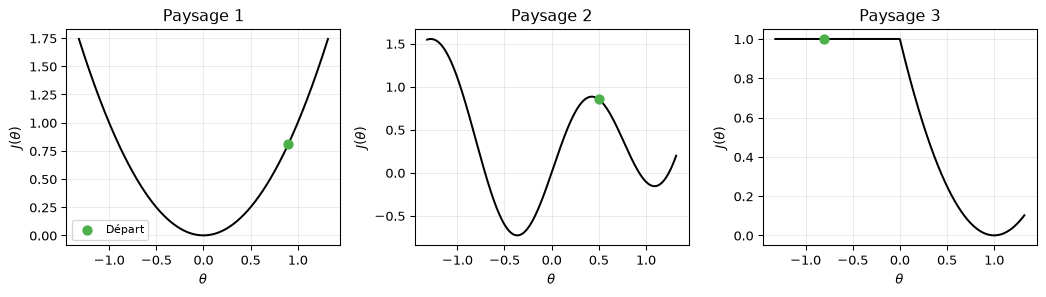

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def gradient_descent_1d(gradient, start, learning_rate, steps, clip_value=None):
    trajectory = [float(start)]
    for _ in range(steps):
        g = float(gradient(trajectory[-1]))
        if not np.isfinite(g):
            break  # La fonction simplifiée n'a pas de dérivée finie ici.
        if clip_value is not None:
            g = np.clip(g, -clip_value, clip_value)
        trajectory.append(trajectory[-1] - learning_rate * g)
    return np.asarray(trajectory)

def plot_landscape(objective, trajectory, ax, title, show_trajectory=True):
    left = min(-1.2, trajectory.min())
    right = max(1.2, trajectory.max())
    padding = 0.05 * (right - left)
    theta = np.linspace(left - padding, right + padding, 800)
    ax.plot(theta, objective(theta), color='black', linewidth=1.5)
    if show_trajectory:
        ax.plot(trajectory, objective(trajectory), 'o-', color='#377eb8',
                markersize=3, linewidth=0.8, alpha=0.65)
    ax.scatter(trajectory[0], objective(trajectory[0]), color='#4daf4a',
               s=45, zorder=4, label='Départ')
    if show_trajectory:
        ax.scatter(trajectory[-1], objective(trajectory[-1]), color='#d95f02',
                   s=45, zorder=5, label='Fin')
    ax.set(title=title, xlabel=r'$\theta$', ylabel=r'$J(\theta)$')
    ax.grid(alpha=0.25)
    return theta


fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
overview = [
    ('Référence convexe', lambda t: t**2, lambda t: 2*t, 0.9, 0.1),
    ('Minima locaux', lambda t: 0.8*np.sin(4*t)+0.5*t**2,
     lambda t: 3.2*np.cos(4*t)+t, 0.5, 0.05),
    ('Région plate sous-optimale', lambda t: (np.maximum(0, t)-1)**2,
     lambda t: 2*(t-1) if t > 0 else 0.0, -0.8, 0.1)
]
for index, (ax, (_, objective, gradient, start, rate)) in enumerate(zip(axes, overview)):
    trajectory = gradient_descent_1d(gradient, start, rate, steps=60)
    plot_landscape(objective, trajectory, ax, f'Paysage {index+1}',
                   show_trajectory=False)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

Chaque graphique présente une fonction objectif et une valeur initiale
du paramètre, avant de révéler les mises à jour. Le gradient décrit la
pente au point courant; il n’examine pas tout le paysage. Une région
horizontale peut donc arrêter les mises à jour, même si de meilleures
valeurs existent ailleurs. La figure suivante montre les trajectoires
produites par la procédure de descente de gradient indiquée.

**Les trois fonctions objectif sont-elles différentiables partout?** Les
deux premières le sont. La troisième,
$J(\theta)=(\operatorname{ReLU}(\theta)-1)^2$, présente un point
anguleux à $\theta=0$ : la pente à gauche vaut 0 et celle à droite vaut
$-2$. La dérivée n’est donc pas définie à ce point. La région plate où
$\theta<0$ est différentiable, avec une dérivée nulle.

Les cadriciels fournissent des règles de rétropropagation pour les
opérations usuelles à de tels points anguleux. La fonction `torch.relu`
de PyTorch utilise zéro à son point anguleux; autograd retourne donc
aussi zéro pour la troisième fonction objectif à $\theta=0$,
conformément à la règle utilisée dans cet exemple. PyTorch peut ainsi
calculer des valeurs pour le passage arrière des trois fonctions
lorsqu’elles sont exprimées à l’aide de ses opérations sur les tenseurs.
Cette convention ne rend pas la troisième fonction différentiable
partout et n’aide pas la descente de gradient à quitter sa région plate.
Voir <a
href="https://docs.pytorch.org/docs/stable/notes/autograd.html#gradients-for-non-differentiable-functions"
class="external" data-icon="true">PyTorch : gradients des fonctions non
différentiables</a>.

## Trois paysages, trois trajectoires

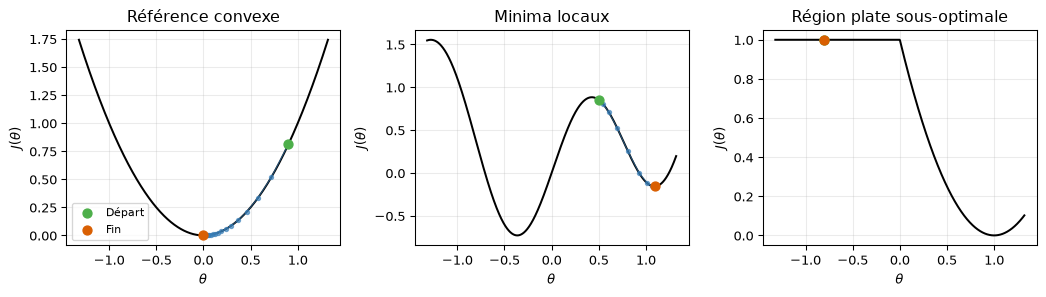

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (title, objective, gradient, start, rate) in zip(axes, overview):
    trajectory = gradient_descent_1d(gradient, start, rate, steps=60)
    plot_landscape(objective, trajectory, ax, title)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

[Paysages de perte et descente de gradient ](loss_functions.qmd) :
expériences complètes, cartes thermiques et comparaisons avec écrêtage.

La fonction convexe de référence approche son minimum. Dans l’exemple
non convexe, le point initial détermine le minimum local atteint. Dans
le troisième exemple, $J(\theta)=(\operatorname{ReLU}(\theta)-1)^2$ :
toute valeur négative du paramètre produit une perte de 1 et un gradient
nul, alors que $\theta=1$ donne une perte nulle. Il s’agit d’une région
plate sous-optimale, et non d’une fonction objectif constante partout.

Le carnet complémentaire présente aussi des fonctions objectif
simplifiées singulières et discontinues. Elles illustrent des situations
où la différentiabilité ordinaire fait défaut. Il faut les distinguer de
l’atténuation ou de l’amplification des gradients à travers les couches
d’un réseau.

Dans ces exemples, une discontinuité correspond à un saut de la valeur
de la fonction objectif. La pointe de la fonction racine carrée possède
une dérivée dont la valeur absolue devient arbitrairement grande à
proximité de la pointe. Ces propriétés concernent la fonction simplifiée
elle-même; la section suivante étudie plutôt les produits de dérivées
finies dans un réseau.

# Propagation des gradients et initialisation

## Que se passe-t-il sur un chemin plus long?

La présentation 13 utilisait une seule unité cachée. Que se passe-t-il
lorsque de nombreuses transformations du passage arrière se composent?

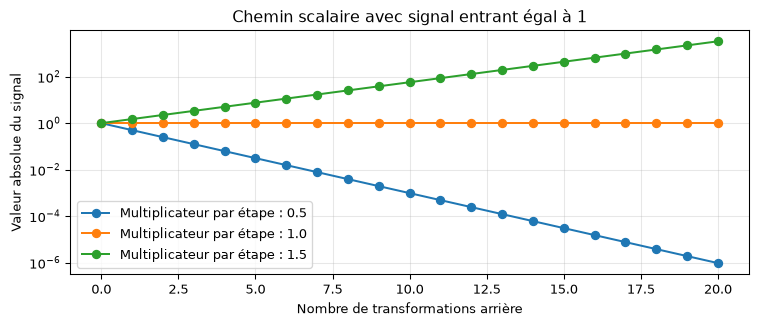

In [3]:
distance = np.arange(21)
fig, ax = plt.subplots(figsize=(8, 3.5))
for factor in (0.5, 1.0, 1.5):
    ax.semilogy(distance, factor**distance, 'o-', label=f'Multiplicateur par étape : {factor}')
ax.set(xlabel='Nombre de transformations arrière', ylabel='Valeur absolue du signal',
       title='Chemin scalaire avec signal entrant égal à 1')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

$\delta_l=w_{l+1}\varphi'(z_l)\,\delta_{l+1}$, où $w_{l+1}\varphi'(z_l)$
est le **multiplicateur par étape**.

Le **multiplicateur par étape**, aussi appelé ici facteur local, combine
un poids et une dérivée d’activation. Rappelons la notation scalaire de
la présentation 13 : $z_l$ est la préactivation de l’unité à la couche
$l$, $w_{l+1}$ est le poids qui la relie à l’unité suivante et le
**signal d’erreur** $\delta_l=\partial\ell/\partial z_l$ mesure la
sensibilité de la perte à cette préactivation. Avec une unité par
couche, la rétropropagation donne

$$
\delta_l=\underbrace{w_{l+1}\varphi'(z_l)}_{q_l}\,\delta_{l+1}.
$$

Le facteur $\varphi'(z_l)$ est la dérivée locale de l’activation,
évaluée à la préactivation conservée en mémoire. Ainsi, $q_l$ est le
multiplicateur appliqué lorsque le signal progresse d’une étape vers
l’entrée. Il ne s’agit ni du taux d’apprentissage ni du gradient complet
d’un paramètre. Le graphique utilise délibérément le **même
multiplicateur positif $q$ à chaque étape**, à partir d’un signal de
valeur absolue 1. Après $d$ étapes arrière, la valeur absolue est $q^d$
: $q=0.5$ la divise par deux à chaque étape, $q=1$ la préserve et
$q=1.5$ l’augmente de 50 % par étape. L’axe vertical est logarithmique
pour rendre visibles l’atténuation et l’amplification.

Dans un réseau réel, les facteurs dépendent de la couche et de
l’exemple, peuvent être négatifs et ne sont pas nécessairement égaux. Un
facteur négatif peut inverser le signe du signal; ce graphique utilise
des facteurs positifs pour isoler les changements de valeur absolue.

Les paysages illustraient la géométrie locale d’une fonction objectif.
Cet exemple isole un autre mécanisme : la composition de nombreuses
dérivées locales peut modifier considérablement l’échelle du signal,
même si chaque facteur est fini.

Cette illustration suit un seul chemin. Un réseau général additionne
aussi les contributions aux embranchements, comme dans la présentation
13. La borne de $0.25$ de la dérivée sigmoïde ne borne pas tous les
gradients complets des paramètres, puisque les poids et d’autres chemins
contribuent aussi.

## Gradients évanescents

- La rétropropagation multiplie de façon répétée des **poids et des
  dérivées locales d’activation**.
- De petits facteurs peuvent rendre les gradients des premières couches
  trop faibles pour un apprentissage efficace.
- Les unités sigmoïdes saturées ont des dérivées proches de zéro.

Rappel : $\sigma'(z)=\sigma(z)(1-\sigma(z))\leq 0.25$.

L’exemple scalaire de la présentation 13 contenait une dérivée
d’activation cachée. Un réseau plus profond introduit davantage de
facteurs de ce type sur chaque chemin. La dérivée sigmoïde approche zéro
pour des préactivations très positives ou très négatives; les unités
saturées peuvent donc fortement atténuer le signal propagé vers l’amont.
Il s’agit du problème des gradients évanescents (*vanishing gradients*).

Une activation est **saturée** lorsque modifier son entrée produit très
peu de changement à sa sortie : sa dérivée locale est alors proche de
zéro. Pour une sigmoïde, cela se produit près des deux extrémités de son
intervalle de sortie. **En amont** signifie vers les entrées dans le
calcul arrière; **en aval** signifie vers la sortie et la perte.

Les poids entrent aussi dans ces produits et les différents chemins
apportent des sommes : la borne de $0.25$ de la dérivée locale d’une
sigmoïde ne borne pas chaque gradient complet d’un paramètre. Les
gradients peuvent diminuer ou augmenter selon les transformations
combinées. Les gradients évanescents et explosifs peuvent survenir dans
les réseaux à propagation avant comme dans les réseaux récurrents.

Pour une sortie sigmoïde et l’entropie croisée binaire, le signal
d’erreur de sortie se simplifie en $\hat p-y$. Le facteur sigmoïde
explicite s’y annule, mais les unités sigmoïdes cachées contribuent
toujours leurs dérivées d’activation. La formule simplifiée à la sortie
ne supprime donc pas le problème des couches cachées.

## Gradients explosifs

- Des transformations répétées peuvent **amplifier** les signaux du
  passage arrière.
- De grands gradients peuvent produire de **grandes mises à jour des
  paramètres** et un entraînement instable.
- Une initialisation adaptée et un taux d’apprentissage raisonnable
  aident; l’**écrêtage des gradients** peut limiter les mises à jour.

Les gradients explosifs (*exploding gradients*) n’exigent pas une
activation de dérivée infinie. Multiplier une suite de transformations
finies peut suffire. Cette difficulté peut survenir dans les réseaux à
propagation avant et récurrents. Les grandes dérivées près de la pointe
d’une fonction scalaire relèvent d’un autre mécanisme, même si
l’écrêtage peut borner une mise à jour dans les deux cas.

## Fonctions d’activation et dérivées

Quelles pentes préservent un signal utile au passage arrière? ReLU
résout-elle tous les problèmes?

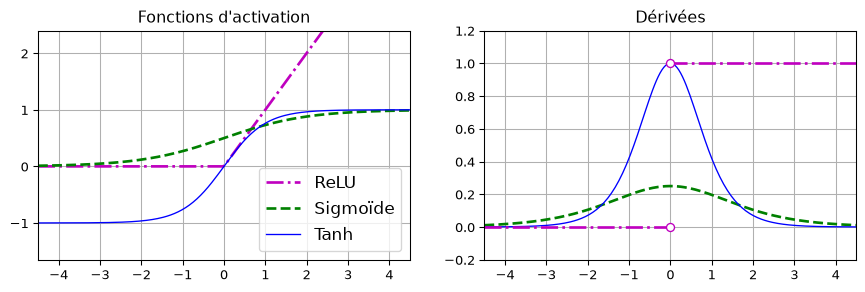

In [4]:
# Attribution: https://github.com/ageron/handson-ml3/blob/main/10_neural_nets_with_keras.ipynb

import numpy as np
import matplotlib.pyplot as plt

from scipy.special import expit as sigmoid

def relu(z):
    return np.maximum(0, z)

def derivative(f, z, eps=0.000001):
    return (f(z + eps) - f(z - eps))/(2 * eps)

max_z = 4.5
z = np.linspace(-max_z, max_z, 200)

plt.figure(figsize=(11, 3.1))

plt.subplot(121)
plt.plot(z, relu(z), "m-.", linewidth=2, label="ReLU")
plt.plot(z, sigmoid(z), "g--", linewidth=2, label="Sigmoïde")
plt.plot(z, np.tanh(z), "b-", linewidth=1, label="Tanh")
plt.grid(True)
plt.title("Fonctions d'activation")
plt.axis([-max_z, max_z, -1.65, 2.4])
plt.gca().set_yticks([-1, 0, 1, 2])
plt.legend(loc="lower right", fontsize=13)

plt.subplot(122)
plt.plot(z, derivative(sigmoid, z), "g--", linewidth=2, label="Sigmoïde")
plt.plot(z, derivative(np.tanh, z), "b-", linewidth=1, label="Tanh")
plt.plot([-max_z, 0], [0, 0], "m-.", linewidth=2)
plt.plot([0, max_z], [1, 1], "m-.", linewidth=2)
plt.plot([0, 0], [0, 1], "mo", markersize=6, markerfacecolor="white")
plt.grid(True)
plt.title("Dérivées")
plt.axis([-max_z, max_z, -0.2, 1.2])

plt.show()

Géron (2022) – <a
href="https://github.com/ageron/handson-ml3/blob/main/10_neural_nets_with_keras.ipynb"
class="external" data-icon="true">10_neural_nets_with_keras.ipynb</a>

Le choix de l’activation influence la propagation des gradients et donc
l’entraînement. Il faut savoir interpréter ces pentes et le rôle de la
règle de dérivation en chaîne, plutôt que dériver manuellement chaque
expression.

La dérivée sigmoïde atteint un maximum de $0.25$ et approche zéro aux
deux extrêmes. La dérivée de $\tanh$ atteint un maximum de un à zéro et
approche aussi zéro dans ses régions saturées.

Pour ReLU, la dérivée vaut zéro lorsque la préactivation est négative et
un lorsqu’elle est positive. À zéro, la dérivée ordinaire n’est pas
définie; les implémentations choisissent une valeur par convention,
souvent zéro. Les cercles ouverts indiquent l’absence de dérivée
ordinaire. L’activation peut prendre toute valeur non négative : c’est
la dérivée, en dehors de zéro, qui vaut zéro ou un.

La **parcimonie** (*sparsity*) signifie que de nombreuses entrées sont
exactement nulles. ReLU produit des activations parcimonieuses
puisqu’elle retourne zéro pour les entrées non positives; cela décrit
les activations de certains exemples, sans affirmer que les poids sont
nuls. Une activation nulle pour un exemple est normale. Une unité qui
demeure dans cette région pour les entrées pertinentes ne reçoit aucun
gradient de la perte des données à travers son activation et peut rester
inactive : c’est le problème des **ReLU mortes** (*dying ReLU*). Il
s’agit d’une inactivité persistante, plutôt que d’une seule sortie
nulle. Des changements des représentations en amont peuvent parfois
réactiver une unité; l’inactivité n’est donc pas toujours irréversible.
Voir <a href="https://arxiv.org/abs/1903.06733" class="external"
data-icon="true">Lu et al. (2019)</a>.

La dérivée de ReLU du côté positif évite une source d’atténuation, sans
rendre le gradient complet égal à un. Les activations entrantes, les
poids en aval, les autres dérivées et les sommes sur les chemins
interviennent aussi. Leaky ReLU conserve une petite pente du côté
négatif, ce qui réduit ce risque particulier.

## Conserver un gradient du côté négatif

Que se passe-t-il si une unité ReLU reste inactive pour les exemples
d’entraînement?

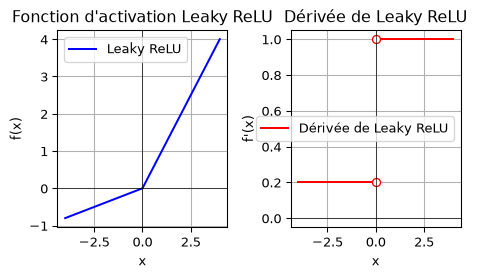

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Définir la fonction Leaky ReLU
def leaky_relu(x, alpha=0.2):
    return np.where(x > 0, x, alpha * x)

# Définir la dérivée de Leaky ReLU
def leaky_relu_derivative(x, alpha=0.2):
    return np.where(x > 0, 1, alpha)

# Générer un intervalle de valeurs d'entrée
x_values = np.linspace(-4, 4, 400)

# Calculer Leaky ReLU et sa dérivée
leaky_relu_values = leaky_relu(x_values)
leaky_relu_derivative_values = leaky_relu_derivative(x_values)

# Créer le graphique
plt.figure(figsize=(5, 3))

# Tracer Leaky ReLU
plt.subplot(1, 2, 1)
plt.plot(x_values, leaky_relu_values, label='Leaky ReLU', color='blue')
plt.title('Fonction d\'activation Leaky ReLU')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)
plt.legend()

# Tracer la dérivée de Leaky ReLU
plt.subplot(1, 2, 2)
plt.plot([-4, 0], [0.2, 0.2], label='Dérivée de Leaky ReLU', color='red')
plt.plot([0, 4], [1, 1], color='red')
plt.plot([0, 0], [0.2, 1], 'o', color='red', markerfacecolor='white')
plt.title('Dérivée de Leaky ReLU')
plt.xlabel('x')
plt.ylabel("f'(x)")
plt.grid(True)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)
plt.legend()

# Afficher les graphiques
plt.tight_layout()
plt.show()

Leaky ReLU, une variante de l’activation ReLU habituelle, atténue le
problème des *unités ReLU mortes*. Pour les entrées négatives, elle
introduit une composante linéaire dont la pente est contrôlée par le
paramètre `negative_slope`.

Leaky ReLU conserve une dérivée non nulle du côté négatif, ce qui réduit
le risque d’inactivité persistante causée par un gradient d’activation
nul. À zéro, sa dérivée ordinaire n’est pas définie si les deux pentes
diffèrent; l’implémentation choisit une convention. Les cercles ouverts
distinguent ce point mathématique de la valeur choisie dans le code.

``` python
import keras

leaky_relu = keras.layers.LeakyReLU(negative_slope=0.2)
dense = keras.layers.Dense(50, activation=leaky_relu, kernel_initializer="he_normal")
```

Voir les
<a href="https://keras.io/api/layers/activations/" class="external"
data-icon="true">fonctions d’activation de Keras</a> pour d’autres
choix.

## Pourquoi ne pas initialiser tous les poids à la même valeur?

Des **poids** initialisés aléatoirement brisent la symétrie entre les
unités. Les **biais** peuvent être initialisés à zéro.

Des unités aux paramètres initiaux identiques et aux rôles identiques
peuvent recevoir les mêmes gradients. L’initialisation aléatoire des
poids leur donne des calculs de départ différents. Une échelle
d’initialisation adaptée à l’activation favorise la propagation des
signaux; elle ne garantit ni convergence ni performance optimale.

## Glorot et Bengio

Des poids aléatoires brisent la symétrie. Leur échelle importe-t-elle?

Activations

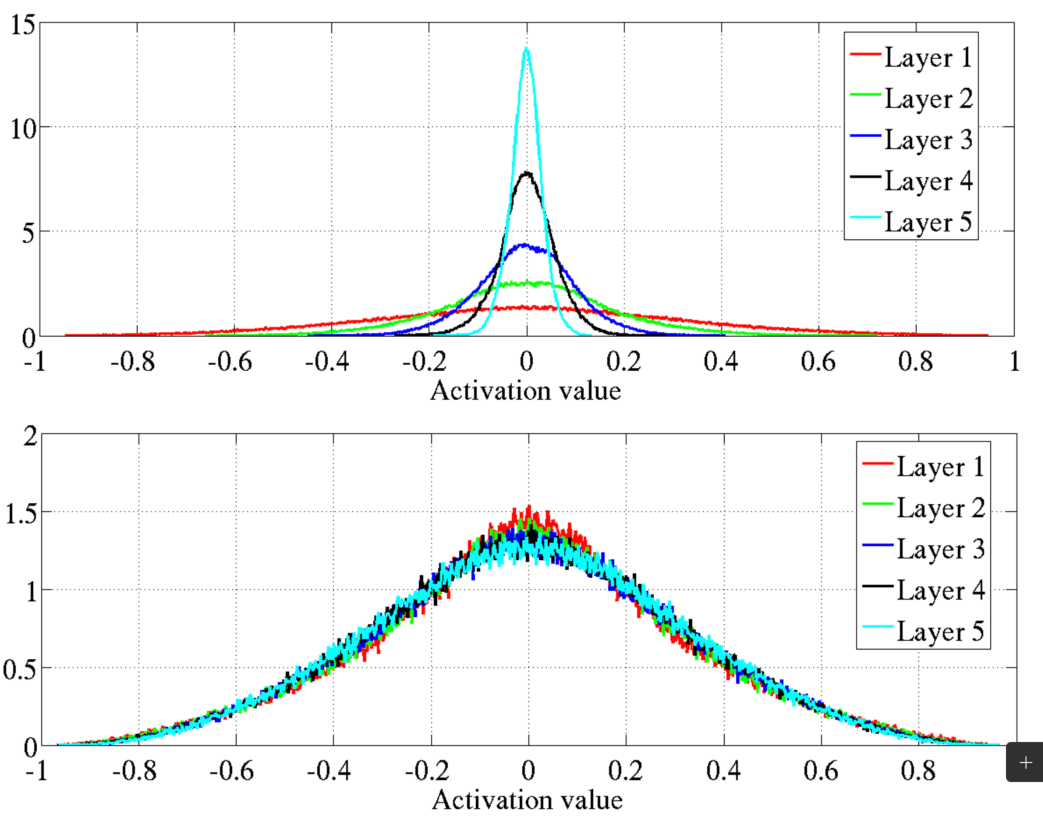

Signaux du passage arrière

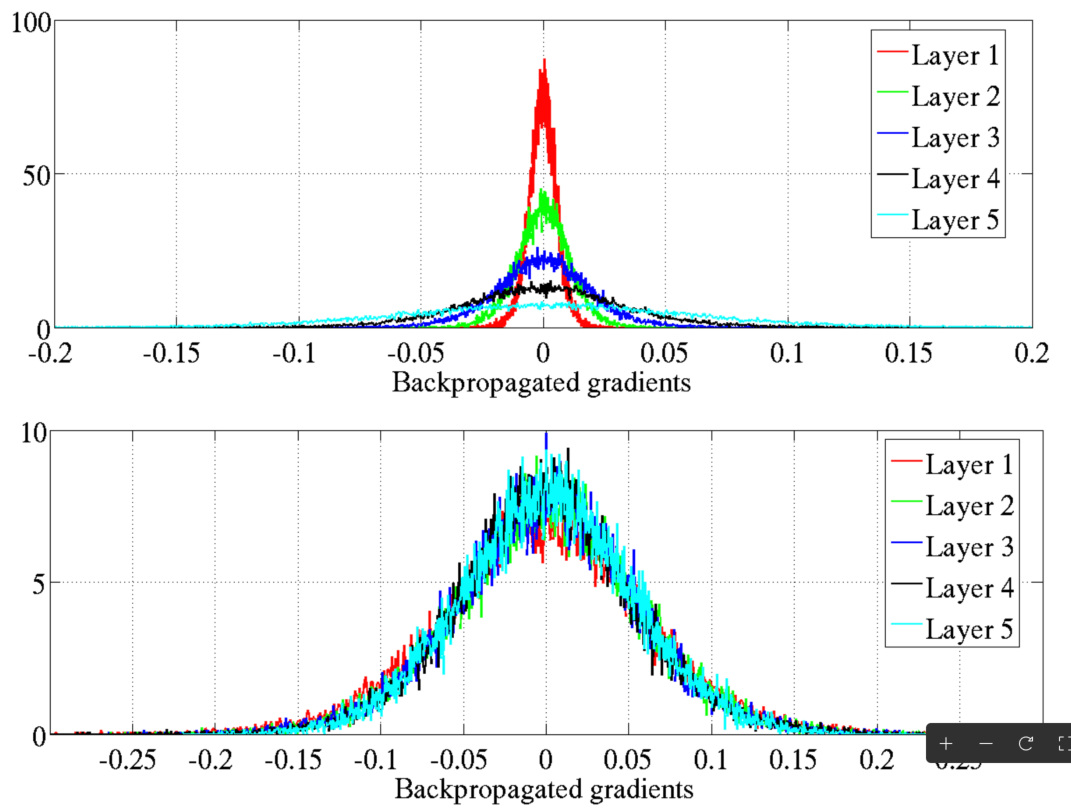

Glorot et Bengio (2010), page 254.

Ces figures comparent une initialisation habituelle (en haut) à
l’initialisation normalisée proposée par Glorot et Bengio (en bas), pour
un réseau d’unités $\tanh$ (Glorot et Bengio 2010, 254). La figure 6
présente les histogrammes des activations et la figure 7 ceux des
gradients rétropropagés. Avec l’initialisation habituelle, les
activations se concentrent davantage près de zéro dans les dernières
couches, tandis que les gradients rétropropagés se concentrent davantage
près de zéro à proximité de l’entrée. Dans ces expériences,
l’initialisation normalisée réduit les différences entre les couches.

Ces distributions correspondent à la configuration rapportée; elles
n’établissent pas une règle universelle selon laquelle des gradients
évanescents impliqueraient toujours de faibles activations au passage
avant. Une sigmoïde saturée peut avoir une activation proche de un et
une dérivée proche de zéro. L’article distingue aussi les signaux
rétropropagés des gradients des poids; leurs distributions selon la
couche ne sont pas nécessairement identiques.

L’initialisation normale de Xavier/Glorot équilibre les dimensions
d’entrée et de sortie de la couche avec
$\operatorname{Var}(W)=2/(n_{\mathrm{in}}+n_{\mathrm{out}})$. Il s’agit
de l’initialisation aléatoire mise à l’échelle déjà utilisée dans
`SimplerMLP`. Ici, $n_{\mathrm{in}}$ et $n_{\mathrm{out}}$ comptent les
entrées et les sorties de la couche. La variance concerne chaque poids
échantillonné; l’écart-type de la distribution normale est la racine
carrée de cette variance.

## Initialisation de He

Pour les couches cachées ReLU, l’initialisation normale de He utilise

$$
\operatorname{Var}(W)=\frac{2}{n_{\mathrm{in}}}.
$$

``` python
def he_init(rng, fan_in, fan_out):
    std = np.sqrt(2.0 / fan_in)
    return rng.normal(0.0, std, size=(fan_in, fan_out))
```

Aussi appelée initialisation de Kaiming.

Cette mise à l’échelle tient compte de l’effet du redresseur sur la
variance du signal. `SimpleMLP` utilisera l’initialisation de He pour
les couches cachées ReLU et celle de Xavier/Glorot pour les couches
sigmoïdes, y compris la sortie. Ce sont des règles d’initialisation,
sans garantie sur l’ensemble de la trajectoire d’entraînement. Voir
<a href="https://arxiv.org/abs/1502.01852" class="external"
data-icon="true">He et al. (2015)</a> pour l’analyse des redresseurs.

## Quels choix favorisent la propagation des gradients?

- **Autres fonctions d’activation** : unité linéaire rectifiée
  (**ReLU**) et variantes, dont **Leaky ReLU**, **Parametric ReLU** et
  **Exponential Linear Unit**.

- **Initialisation des poids** : Xavier (Glorot) ou He.

Les fonctions d’activation et l’initialisation influencent la
propagation des signaux dans les deux directions. ReLU évite la
saturation pour les préactivations positives, mais sa dérivée nulle du
côté négatif crée le risque d’inactivité persistante illustré plus tôt.
L’activation et l’échelle d’initialisation agissent ensemble; aucune ne
garantit des gradients stables dans un réseau arbitrairement profond.
Les **couches de normalisation** et les **connexions résiduelles**
offrent d’autres approches, au-delà de cette implémentation. Même avec
de bonnes conditions initiales, des mises à jour exceptionnellement
grandes restent possibles, ce qui motive le contrôle de la mise à jour
elle-même.

## Écrêtage des gradients

Comment limiter une mise à jour de descente de gradient trop grande tout
en préservant sa direction?

Pour un vecteur gradient $g$ et un seuil $c>0$ :

$$
\widetilde g =
\begin{cases}
g, & \|g\|_2\leq c,\\
c\,g/\|g\|_2, & \|g\|_2>c.
\end{cases}
$$

La mise à jour utilise $\widetilde g$. Sa norme est bornée par $c$.

``` python
optimizer = keras.optimizers.SGD(learning_rate=0.01, global_clipnorm=1.0)
```

L’écrêtage des gradients par norme globale (*global-norm gradient
clipping*) redimensionne le gradient de l’ensemble des paramètres
lorsque nécessaire, tout en préservant sa direction. Il diffère de
l’écrêtage de chaque composante séparément; les deux coïncident pour un
gradient scalaire. Avec un taux d’apprentissage $\alpha$, la mise à jour
de descente de gradient correspondante a une norme d’au plus $\alpha c$.

Ici, $g$ regroupe les dérivées par rapport à tous les paramètres dans un
même vecteur; chaque composante correspond à un poids ou à un biais. Sa
**norme L2 ou euclidienne** est $\|g\|_2=\sqrt{\sum_j g_j^2}$,
c’est-à-dire sa longueur. Le seuil $c$ borne cette longueur combinée,
plutôt que chaque composante séparément. Les définitions générales des
normes apparaissent plus loin, dans la section sur la régularisation.

L’écrêtage ne corrige pas les gradients évanescents et ne garantit pas
la convergence. Le carnet complémentaire compare les mises à jour avec
et sans écrêtage dans les mêmes conditions et présente un exemple à
pointe où des pas constants continuent d’osciller. L’initialisation,
l’activation, l’écrêtage et l’évolution du taux d’apprentissage traitent
différents aspects de l’entraînement.

## Décroissance du taux d’apprentissage

Des pas plus petits peuvent-ils aider plus tard dans l’entraînement? Et
si on les réduit trop tôt?

À l’époque $t=1,2,\ldots$, avec un facteur de décroissance $0<\gamma<1$
:

$$
\alpha_t=\alpha_1\gamma^{t-1}.
$$

``` python
if self.lr_decay is not None:
    self.lr = self.base_lr * self.lr_decay ** (ep - 1)
```

La première époque utilise le taux d’apprentissage initial; les
suivantes utilisent des pas progressivement plus petits. Avec
`lr_decay=None`, le taux reste constant. La décroissance modifie la
taille du pas de l’optimiseur, plutôt que les formules des dérivées ou
la fonction objectif. Elle diffère de la régularisation L2 et de la
décroissance des poids. Réduire le taux trop rapidement peut empêcher
des progrès utiles; cela ne corrige pas les gradients évanescents.

Une **époque** (*epoch*) désigne ici un passage sur tous les exemples
d’entraînement, éventuellement répartis en mini-lots. La **décroissance
des poids** (*weight decay*) consiste à réduire directement les poids
lors des mises à jour des paramètres.

# Couches de sortie

## Changer l’activation de sortie?

Nous avons remplacé une sigmoïde cachée par ReLU. Faut-il faire de même
à la sortie?

Pour la **régression**, la sortie doit respecter les dimensions et
l’intervalle de valeurs de la cible :

- **Nombre de neurones de sortie** :
  - 1 par dimension
- **Fonction d’activation de sortie** :
  - Linéaire pour les cibles sans contrainte; ReLU/softplus pour les
    cibles non négatives; sigmoïde/tanh pour les cibles bornées.
- **Fonction de perte** :
  - <a
    href="https://www.tensorflow.org/api_docs/python/tf/keras/losses/MeanSquaredError"
    class="external" data-icon="true">MeanSquaredError</a>

Dans un
<a href="https://keras.io/guides/keras_cv/object_detection_keras_cv/"
class="external" data-icon="true">problème de détection d’objets</a>,
déterminer la **boîte englobante** (*bounding box*) illustre une tâche
de régression à sortie multidimensionnelle.

La section précédente modifiait les activations cachées pour influencer
la propagation des gradients. La sortie a une autre obligation : ses
valeurs doivent représenter les prédictions requises. Remplacer la
sigmoïde de sortie par ReLU modifie les sorties possibles et leur
interprétation, plutôt que d’améliorer simplement une dérivée interne.

Dans un réseau à propagation avant, les activations cachées sont
choisies surtout pour leurs effets sur la performance et la convergence,
tandis que l’activation de sortie dépend des exigences de la tâche.

- **Couches cachées :**

  La fonction d’activation, par exemple sigmoïde, tanh ou ReLU,
  influence surtout la *dynamique d’entraînement* : propagation des
  gradients, forme de la non-linéarité et vitesse de convergence. Le
  choix est généralement empirique et guidé par la performance, la
  stabilité numérique et le comportement de l’optimisation.

- **Couche de sortie :**

  La fonction d’activation est déterminée par la **nature de la tâche de
  prédiction** :

  - *Régression* : linéaire, ReLU ou softplus, selon les contraintes de
    valeurs
  - *Classification binaire* : sigmoïde
  - *Classification multiclasse* : softmax
  - *Classification multiétiquette* : sigmoïde par unité de sortie

**Softplus** est la fonction lisse
$\operatorname{softplus}(z)=\log(1+e^z)$. Elle produit des valeurs
strictement positives pour des entrées finies et approche zéro pour des
entrées très négatives; elle constitue donc une option pour une
régression à sorties positives. ReLU peut aussi représenter un zéro
exact. Une activation de sortie **linéaire** correspond à l’identité :
la sortie est le score affine lui-même. Voir les
<a href="https://keras.io/api/layers/activations/" class="external"
data-icon="true">définitions des activations de Keras</a>.

Voici des exemples de **régression à sorties multiples** (2 à 4 sorties)
:

- **2 sorties :**

  - Prédire la **latitude et la longitude** d’un lieu à partir d’une
    image.
  - Estimer la **largeur et la hauteur** d’une boîte englobante en
    détection d’objets.
  - Prévoir simultanément la **température et l’humidité**.

- **3 sorties :**

  - Prédire les **coordonnées x, y, z** d’un point dans l’espace, par
    exemple une articulation de la main.
  - Estimer les **valeurs de couleur RVB** à partir de mesures
    spectrales.

- **4 sorties :**

  - Prédire les **coordonnées d’une boîte englobante**,
    $(x_{min}, y_{min}, x_{max}, y_{max})$, en détection d’objets.

## Ces probabilités décrivent-elles un choix exclusif?

Des sigmoïdes distinctes donnent $[0.8,\;0.7,\;0.1]$. Plusieurs
étiquettes peuvent-elles s’appliquer? Une seule classe peut-elle
s’appliquer?

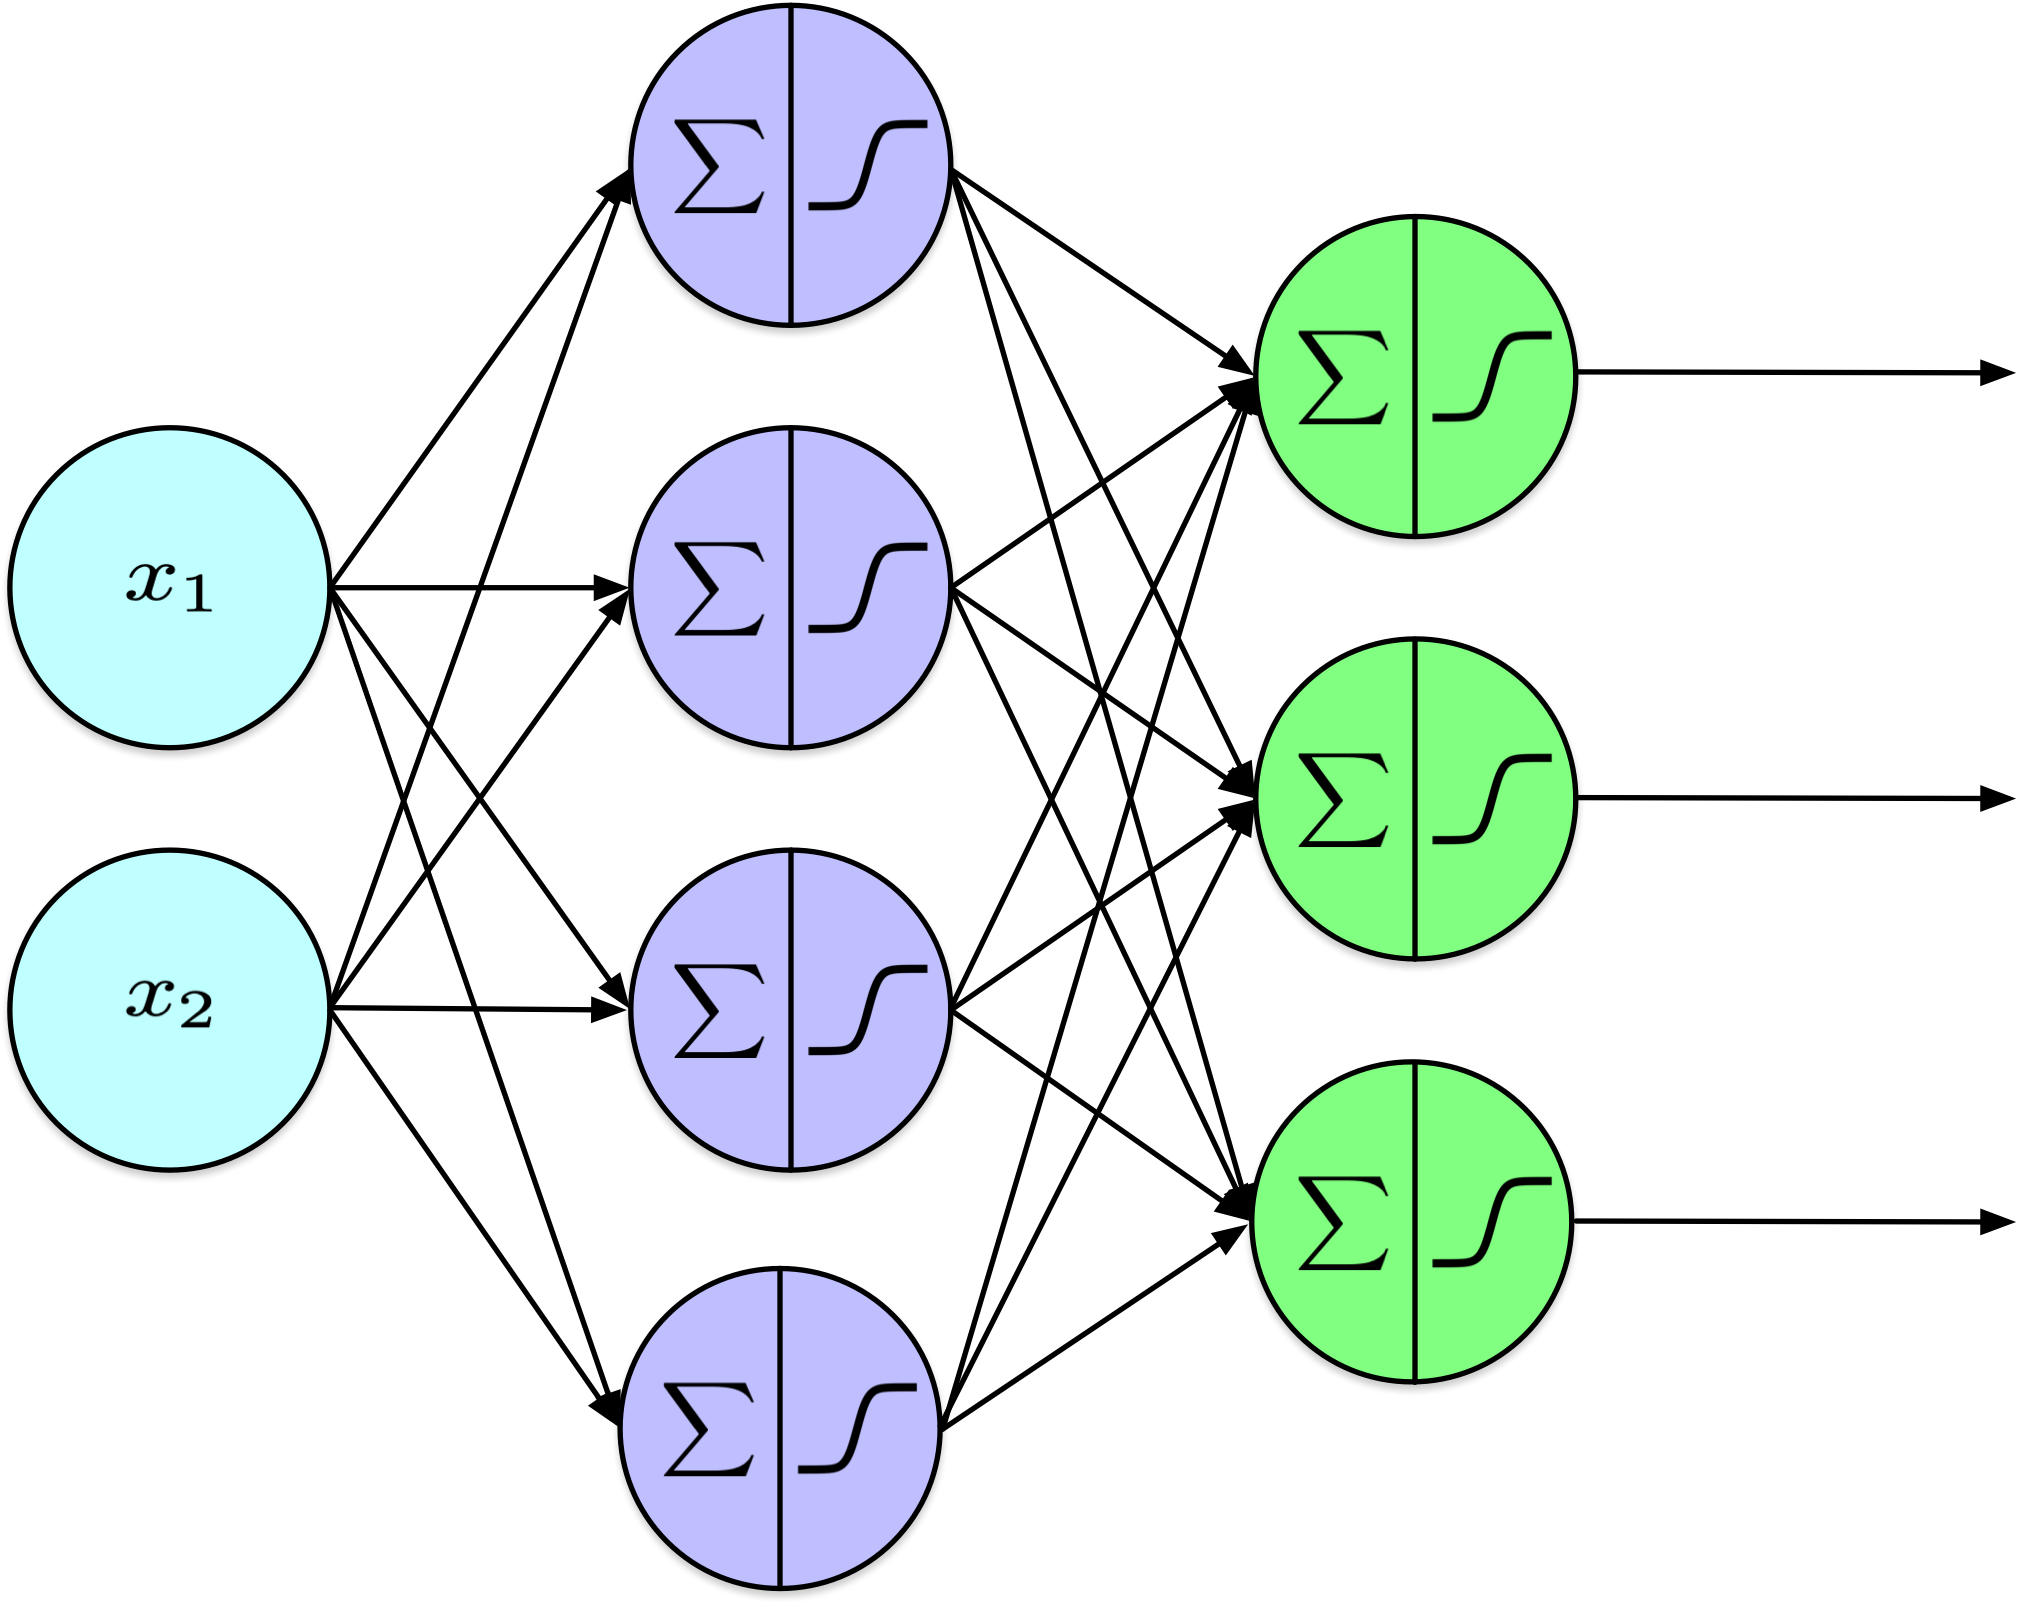

Des sorties sigmoïdes indépendantes conviennent aux prédictions
multiétiquettes; leurs probabilités n’ont pas à totaliser un.

Les valeurs proposées totalisent 1.6. Elles peuvent représenter les
probabilités d’étiquettes distinctes qui coexistent, par exemple
plusieurs objets présents dans une image. Elles ne constituent pas
directement une distribution sur un ensemble exhaustif de classes
mutuellement exclusives, dont les probabilités doivent totaliser un.
Cette différence concerne le sens des sorties, et pas seulement le
nombre d’unités de sortie.

## Une distribution commune à la sortie

Quelles propriétés la sortie doit-elle avoir lorsqu’une seule des $K$
classes est correcte?

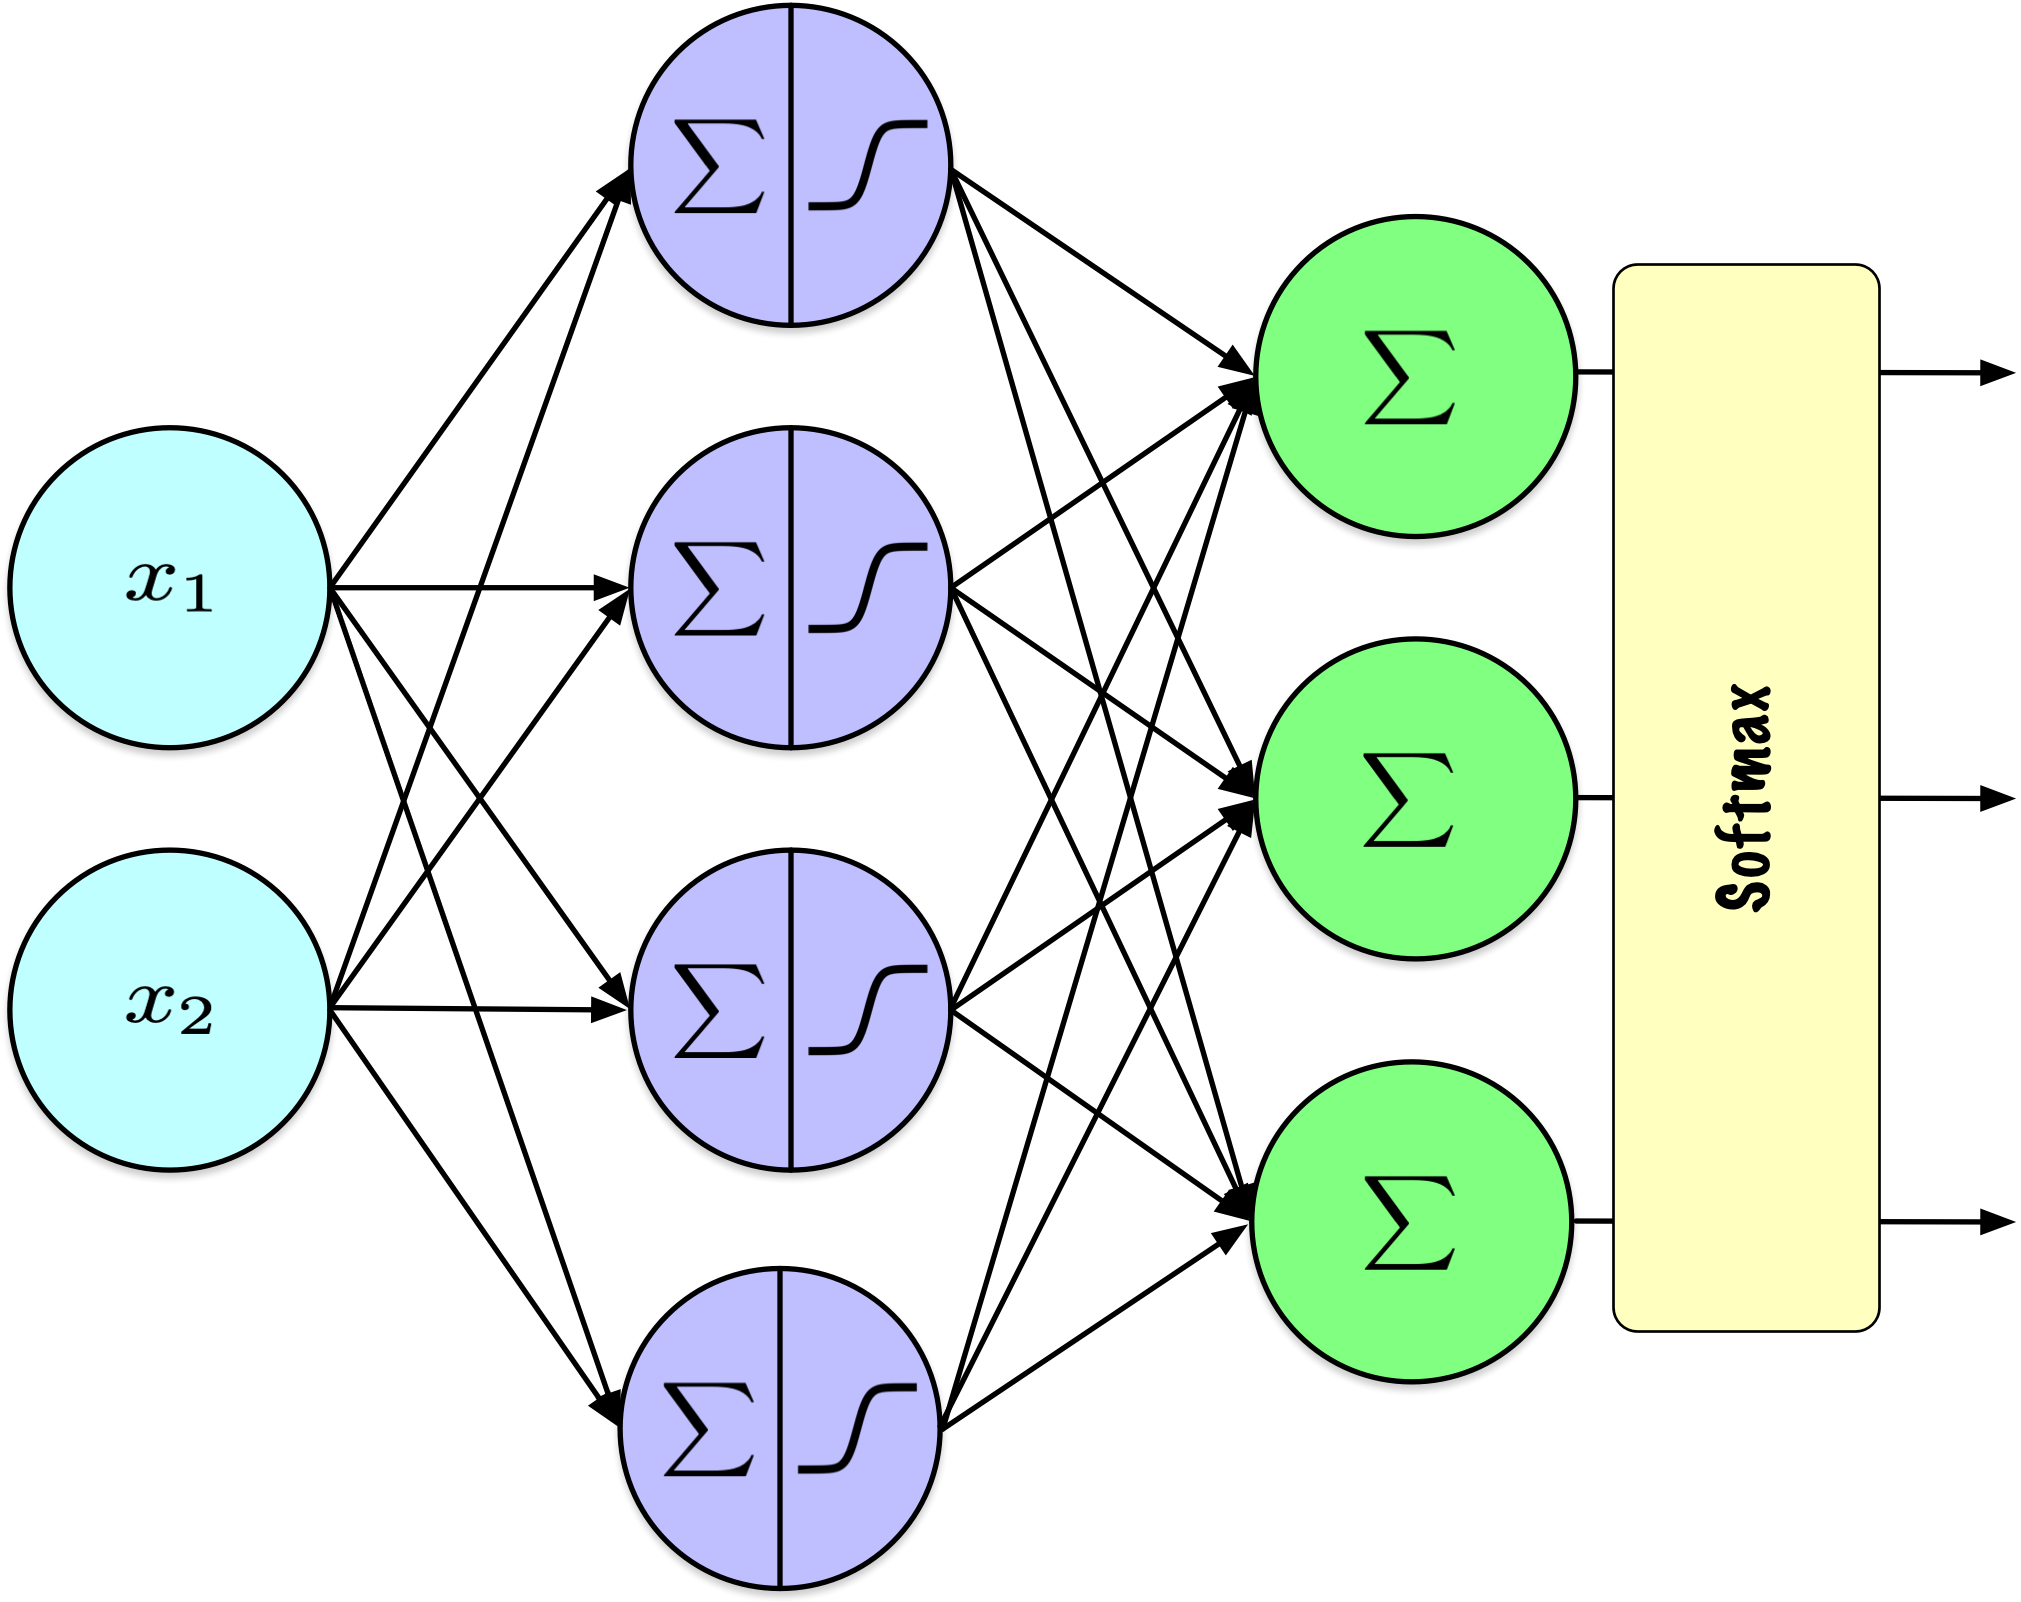

**Softmax** garantit que les sorties d’activation sont comprises entre 0
et 1 et que leur somme vaut 1.

Un **logit** de sortie est un score réel sans contrainte, avant que la
sigmoïde ou softmax finale transforme les scores en probabilités. Dans
le diagramme, les logits sont les préactivations de la couche de sortie.
Softmax s’applique à tout le vecteur de sortie : chaque probabilité
dépend de tous les logits, par le dénominateur commun. Pour une tâche
multiétiquette, les sigmoïdes sont plutôt calculées élément par élément
et leurs sorties n’ont pas à totaliser un.

Les propriétés recherchées motivent cette construction : les sorties
doivent être non négatives, totaliser un et permettre le calcul des
gradients. Softmax est une manière différentiable courante d’obtenir
cette distribution à partir de scores sans contrainte; ces exigences ne
déterminent toutefois pas à elles seules sa formule exponentielle.

La fonction $\operatorname{argmax}$ ne convient pas à l’optimisation par
gradient : elle est constante par morceaux, avec des dérivées nulles en
dehors des égalités et des dérivées non définies aux frontières
pertinentes. Softmax offre une interprétation probabiliste et une
dérivée calculable, ce qui la rend plus adaptée à ces applications.

La fonction $\operatorname{argmax}$ peut être appliquée *a posteriori* à
un réseau entraîné pour prédire une classe.

Comme dans la présentation 11, **argmax** retourne l’indice d’une plus
grande entrée. Elle choisit une classe, tandis que softmax retourne tout
le vecteur des probabilités de classe.

## Des scores à une distribution de probabilités

La fonction **softmax** est une **fonction d’activation** utilisée en
**classification multiclasse** pour convertir un vecteur de scores bruts
en **probabilités dont la somme vaut 1**.

Pour $K$ logits de sortie $\mathbf{z} = [z_1, z_2, \ldots, z_K]$ :

$$
\hat p_k=\operatorname{softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}
$$

Ici, $\hat p_k$ est la probabilité prédite pour la classe $k$.

Les logits de sortie sont des scores réels. L’exponentiation rend leurs
valeurs transformées positives et la normalisation porte la somme des
probabilités à un. Des logits égaux donnent une probabilité $1/K$ à
chaque classe. Ajouter une même constante à tous les logits ne change
pas les probabilités.

Softmax préserve l’ordre : le plus grand logit et la plus grande
probabilité désignent la même classe. Les rapports de probabilités
satisfont $\hat p_i/\hat p_j=e^{z_i-z_j}$. Ces scores relatifs ne
garantissent pas une prédiction correcte. Une distribution de
probabilités peut généralement contenir des zéros; la positivité est une
propriété de softmax mathématique pour des logits finis.

## Que signifient les écarts entre les scores?

Quelle classe l’emporte? Comment l’écart entre les scores influence-t-il
sa probabilité?

|    $z_1$ |    $z_2$ |    $z_3$ | $\hat p_1$ | $\hat p_2$ | $\hat p_3$ | $\sum$ |
|---------:|---------:|---------:|-----------:|-----------:|-----------:|-------:|
| **1.47** |    -0.39 |     0.22 |   **0.69** |       0.11 |       0.20 |   1.00 |
|     5.00 | **6.00** |     4.00 |       0.24 |   **0.67** |       0.09 |   1.00 |
|     0.90 |     0.80 | **1.10** |       0.32 |       0.29 |   **0.39** |   1.00 |
|    -2.00 | **2.00** |    -3.00 |       0.02 |   **0.98** |       0.01 |   1.00 |

Valeurs de softmax pour un vecteur de longueur 3.

1.  **Préservation de l’ordre relatif** : si une entrée est plus grande
    qu’une autre, la sortie softmax correspondante est aussi plus
    grande.

2.  **Interprétation probabiliste** : chaque valeur est comprise entre 0
    et 1. Les sorties sont normalisées pour totaliser un, ce qui permet
    de les interpréter comme des probabilités.

3.  **Écarts relatifs** : lorsque les écarts entre les logits sont
    petits, les probabilités restent proches de la distribution
    uniforme. Si tous les logits sont identiques, chaque probabilité
    vaut $\frac{1}{K}$.

4.  **Arrondi** : dans la dernière ligne, les probabilités affichées
    peuvent totaliser 1.01, car chaque entrée a été arrondie séparément.
    Les probabilités non arrondies totalisent un. La stabilité numérique
    exige le calcul décalé présenté ci-dessous.

Ces propriétés rendent softmax particulièrement utile pour les tâches de
classification multiclasse en apprentissage automatique.

**Calculer softmax de manière stable**

Que se passe-t-il si les logits valent $1000$, $1001$ et $999$?

Soustraire le plus grand logit ne change pas les probabilités :

$$
\hat p_k=\frac{e^{z_k-m}}{\sum_j e^{z_j-m}},\qquad m=\max_j z_j.
$$

Exponentier directement de très grands scores positifs peut causer un
dépassement de capacité. Soustraire le maximum évite ce dépassement. De
très petites probabilités peuvent néanmoins subir un sous-dépassement;
les bibliothèques utilisées en pratique combinent donc habituellement la
perte aux logits à l’aide de calculs log-sum-exp stables. Voir <a
href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.softmax.html"
class="external" data-icon="true">softmax dans SciPy</a>.

Un **dépassement de capacité** (*overflow*) se produit lorsqu’une valeur
calculée dépasse l’intervalle de la représentation en virgule flottante;
un **sous-dépassement** (*underflow*) peut arrondir à zéro un résultat
non nul suffisamment petit. Un calcul **numériquement stable** évite les
pertes inutiles de précision ou d’étendue causées par les opérations
intermédiaires.

**Log-sum-exp** désigne la fonction $\log\left(\sum_j e^{z_j}\right)$.
Elle peut être évaluée sous la forme décalée

$$
\log\left(\sum_j e^{z_j}\right)
=m+\log\left(\sum_j e^{z_j-m}\right),\qquad m=\max_j z_j.
$$

Une implémentation combinée de l’entropie croisée peut utiliser cette
expression au lieu de prendre le logarithme d’une probabilité déjà
arrondie à zéro par sous-dépassement. Voir <a
href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.logsumexp.html"
class="external" data-icon="true">logsumexp dans SciPy</a>.

Si la dernière couche Dense retourne des logits, utiliser une perte
d’entropie croisée configurée avec `from_logits=True`. Si elle retourne
des probabilités softmax, utiliser `from_logits=False`. Appliquer
softmax, puis déclarer que les valeurs sont des logits, modifie la
fonction objectif.

L’annexe présente un [exemple exécutable](#stable-softmax-computation)
du calcul décalé de softmax.

## Limites

Quelles limites pouvez-vous proposer?

Notre classifieur Fashion-MNIST reçoit l’image d’un **7** manuscrit. Que
prédira-t-il?

Softmax répartit toute la probabilité entre les **classes connues**.
Aucune sortie **« aucune de ces classes »** n’est prévue.

Le classifieur Fashion-MNIST possède des sorties pour des classes de
vêtements, et non pour des chiffres manuscrits. Face à un 7 manuscrit,
il produit quand même des probabilités pour ces classes de vêtements.
Appliquer argmax choisit l’une d’elles, même si aucune ne décrit
correctement l’entrée. Softmax construit un vecteur de probabilités;
argmax prend la décision de classe.

Un exemple d’une classe absente de la tâche d’entraînement est une
entrée **hors distribution** (*out-of-distribution*). Une telle entrée
peut recevoir une forte probabilité prédite pour une classe connue. Les
probabilités totalisent un à cause de la transformation de sortie, et
non parce que le modèle a établi qu’une de ses classes connues
s’applique.

L’utilisation de softmax suivie d’argmax ne produit donc aucune réponse
automatique « je ne sais pas ». Une application peut ajouter une règle
qui rejette certaines entrées au lieu de retourner une classe. Par
exemple, elle peut comparer la plus grande probabilité prédite à un
seuil. Cela peut aider, mais des entrées inhabituelles peuvent encore
recevoir de fortes probabilités et échapper au rejet. Voir
<a href="https://arxiv.org/abs/1610.02136" class="external"
data-icon="true">Hendrycks et Gimpel, <em>A Baseline for Detecting
Misclassified and Out-of-Distribution Examples in Neural
Networks</em></a>.

## Peut-on se fier aux probabilités?

Parmi de nombreuses prédictions faites avec environ **90 % de
confiance**, quelle proportion devrait être correcte?

Environ **90 %**, si le modèle est **bien calibré**.

Des probabilités qui totalisent un ne garantissent pas une bonne
calibration.

La **confiance** désigne ici la plus grande probabilité de classe
prédite, associée à la classe choisie par argmax. La **calibration des
probabilités** (*probability calibration*) concerne l’accord entre les
probabilités prédites et les fréquences observées. Parmi de nombreux
exemples pour lesquels la classe choisie reçoit une probabilité proche
de 0.9, un classifieur bien calibré devrait avoir raison environ 90 % du
temps. Cet accord devrait aussi tenir aux autres niveaux de confiance.
Il s’agit d’une propriété de groupes de prédictions, sans garantie pour
un exemple individuel.

L’exactitude mesure la fréquence à laquelle la classe choisie est
correcte. La calibration demande si la confiance annoncée correspond à
cette fréquence observée. Un classifieur peut avoir une bonne exactitude
tout en étant trop confiant. La calibration doit être évaluée sur des
données réservées et représentatives de l’utilisation prévue; la
normalisation par softmax ne suffit pas. Voir
<a href="https://proceedings.mlr.press/v70/guo17a.html" class="external"
data-icon="true">Guo et al., <em>On Calibration of Modern Neural
Networks</em></a>.

La calibration et la reconnaissance des classes inhabituelles sont
liées, mais distinctes. Une bonne calibration sur des données familières
ne garantit pas que les entrées de classes inédites seront détectées ou
rejetées.

Pour approfondir, l’**apprentissage profond évidentiel** (*evidential
deep learning*) explore l’apprentissage de la quantité d’éléments
probants qui appuient une classification, en complément des probabilités
de classe. Voir <a
href="https://papers.nips.cc/paper_files/paper/2018/hash/a981f2b708044d6fb4a71a1463242520-Abstract.html"
class="external" data-icon="true">Sensoy, Kaplan et Kandemir,
<em>Evidential Deep Learning to Quantify Classification
Uncertainty</em></a>. Ses estimations d’incertitude doivent être
évaluées; des recherches ultérieures ont relevé des limites des méthodes
existantes. Voir <a
href="https://papers.nips.cc/paper_files/paper/2024/hash/c3177be226ee12e34d6ba3b5e6fe6a5b-Abstract-Conference.html"
class="external" data-icon="true">Shen et al., <em>Are Uncertainty
Quantification Capabilities of Evidential Deep Learning a
Mirage?</em></a>.

## Même classe prédite, même perte?

La vraie classe est Setosa. Les deux prédictions la choisissent :

- $[0.25,\;\mathbf{0.51},\;0.24]$
- $[0.005,\;\mathbf{0.99},\;0.005]$

L’**entropie croisée** récompense la probabilité attribuée à la vraie
classe :

$$
\ell = -\sum_{k=1}^{K} y_k \log(\hat p_k)
$$

Cible encodée en un seul 1 (*one-hot*) : $y$. Probabilités de classe
prédites : $\hat p_k$.

Les deux vecteurs ont leur plus grande composante à la position de
Setosa. L’exactitude traite donc ces prédictions de la même façon,
tandis qu’une fonction objectif fondée sur les probabilités peut les
distinguer. L’entropie croisée donne les pertes
$-\log(0.51)\approx0.6733$ et $-\log(0.99)\approx0.0101$. La perte plus
faible récompense une probabilité plus grande pour la vraie classe. Cela
rappelle l’utilisation, dans la présentation 12, des probabilités de
`forward` plutôt que des étiquettes seuillées de `predict` pour calculer
la BCE.

- La cible $y$ est un vecteur de longueur $K$ encodé en un seul 1
  (*one-hot*) : la composante de la vraie classe vaut 1 et toutes les
  autres valent 0.

- Dans la somme sur les classes, seul le terme associé à la vraie classe
  contribue donc une valeur non nulle.

- La perte d’entropie croisée d’un exemple vaut ainsi $-\log(\hat p_k)$,
  où $\hat p_k$ est la probabilité prédite pour la vraie classe.

- La probabilité $\hat p_k$ provient de softmax appliquée à la couche de
  sortie du réseau.

## Entropie croisée : un exemple détaillé

- **Problème de classification** : 3 classes
  - Versicolour, Setosa, Virginica.
- **Encodage en un seul 1** :
  - Setosa = $[0, 1, 0]$.
- **Sorties softmax et perte** :
  - $[0.22,\mathbf{0.7}, 0.08]$ : perte = $-\log(0.7) = 0.3567$.
  - $[0.7, \mathbf{0.22}, 0.08]$ : perte = $-\log(0.22) = 1.5141$.
  - $[0.7, \mathbf{0.08}, 0.22]$ : perte = $-\log(0.08) = 2.5257$.

Parmi les sorties softmax, l’entropie croisée ne retient que la
composante $k=2$ (Setosa), puisque les autres entrées du vecteur cible
sont nulles. Ici, les indices mathématiques des classes vont de 1 à 3.
La composante pertinente est en gras. Une plus grande probabilité pour
la vraie classe donne une perte plus faible; les trois exemples donnent
respectivement 0.3567, 1.5141 et 2.5257.

## Comment pénaliser les erreurs faites avec confiance?

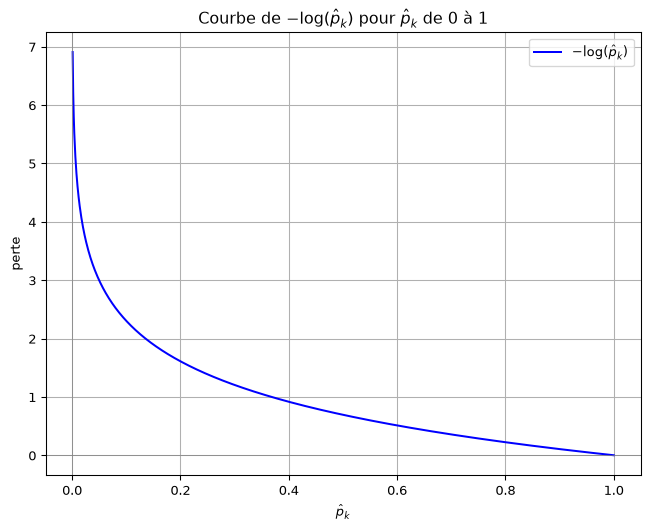

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Générer des valeurs de p strictement positives jusqu’à 1
p_values = np.linspace(0.001, 1, 1000)

# Calculer le logarithme naturel de chaque valeur de p
ln_p_values = - np.log(p_values)

# Tracer le graphique
plt.figure(figsize=(8, 6))
plt.plot(p_values, ln_p_values, label=r'$-\log(\hat p_k)$', color='b')

# Ajouter les étiquettes et le titre
plt.xlabel(r'$\hat p_k$')
plt.ylabel(r'perte')
plt.title(r'Courbe de $-\log(\hat p_k)$ pour $\hat p_k$ de 0 à 1')
plt.grid(True)
plt.axhline(0, color='gray', lw=0.5)  # Ajouter une ligne horizontale à y=0
plt.axvline(0, color='gray', lw=0.5)  # Ajouter une ligne verticale à x=0

# Afficher le graphique
plt.legend()
plt.show()

- Dans la somme, seul le terme où $y_k = 1$ contribue une valeur non
  nulle.

- À cause du signe négatif devant la somme, la valeur de la fonction est
  $-\log(\hat p_k)$.

- Si la probabilité $\hat p_k$ approche 1, la perte approche zéro, ce
  qui indique une faible pénalité.

- Si $\hat p_k$ approche plutôt 0, indiquant une prédiction incorrecte,
  la perte tend vers l’infini. Cela pénalise fortement une probabilité
  très faible pour la vraie classe, sans garantir à soi seul une
  convergence plus rapide.

## D’un exemple à un jeu de données

Pour un jeu de $N$ exemples, la **perte moyenne d’entropie croisée** sur
tous les exemples se calcule ainsi :

$$
J = -\frac{1}{N} \sum_{i=1}^{N} \sum_{k=1}^{K} y_{i,k} \log(\hat p_{i,k})
$$

où :

- $i$ désigne les différents **exemples** du jeu de données.
- $y_{i,k}$ et $\hat p_{i,k}$ sont respectivement les **probabilités
  réelles** et **prédites** de la classe $k$ pour l’exemple $i$.

**Qu’est-ce qui change au passage arrière?**

- **Étiquettes de classe entières** : utiliser l’entropie croisée
  catégorielle à étiquettes entières (*sparse categorical
  cross-entropy*).
- **Cibles encodées en un seul 1** : utiliser l’entropie croisée
  catégorielle.
- Avec softmax et l’entropie croisée catégorielle, le signal de sortie
  d’un exemple est

$$
\frac{\partial\ell}{\partial z_k}=\hat p_k-y_k.
$$

``` python
output_layer = keras.layers.Dense(10)  # Logits : pas de softmax ici.
loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
```

L’équation utilise une cible encodée en un seul 1. Une perte à
étiquettes entières reçoit l’indice de la vraie classe et calcule une
perte équivalente sans stocker ce vecteur. C’est l’équivalent
multiclasse du signal de sortie sigmoïde/BCE de la présentation 13. Il
ne faut pas multiplier le signal déjà simplifié par une dérivée
d’activation supplémentaire. Pour les lots, on moyenne une seule fois
les gradients des paramètres sur les exemples, comme précédemment.

Dans l’**entropie croisée catégorielle à étiquettes entières**, le mot
anglais « sparse » désigne cet encodage compact des cibles. Il ne
signifie pas que les poids du modèle sont parcimonieux.

Les probabilités $\hat p_k$ ne sont pas des décisions de classe. Argmax
donne l’étiquette prédite. `SimpleMLP`, présenté plus loin, conserve une
sortie sigmoïde unique et la BCE; le carnet MNIST utilise Keras pour le
modèle à dix classes.

## Associer sorties et pertes de classification

| Tâche | Unités de sortie | Activation | Perte |
|:-----------------|:-----------------|:-----------------|:-----------------|
| Binaire | Une | Sigmoïde | Entropie croisée binaire |
| Multiétiquette | Une par étiquette | Sigmoïdes distinctes | Entropie croisée binaire |
| Multiclasse | Une par classe | Softmax commune | Entropie croisée catégorielle |

La tâche détermine le sens des sorties et la perte des données à
minimiser.

Ce tableau regroupe les configurations de sorties probabilistes
présentées ci-dessus. Un modèle multiclasse Keras peut aussi retourner
des logits et utiliser une perte catégorielle avec `from_logits=True`;
la variante à étiquettes entières reçoit les indices des classes. Ces
choix définissent la fonction objectif liée aux données. Même un
objectif approprié peut être optimisé au-delà du point où la performance
sur de nouveaux exemples est la meilleure, ce qui motive les courbes de
validation de la section suivante.

## Vidéo complémentaire : argmax et softmax

<https://www.youtube.com/watch?v=KpKog-L9veg>

Cette vidéo complémentaire reprend la distinction entre choisir une
classe et construire des probabilités de classe différentiables. La
section suivante revient à l’entraînement : une perte d’entraînement qui
diminue ne suffit pas à montrer que les prédictions s’améliorent sur de
nouveaux exemples.

# Régularisation

## Définition

La **régularisation** est une modification d’un algorithme
d’apprentissage visant à **réduire son erreur de généralisation**.

## Quelle sauvegarde déploieriez-vous?

L’erreur d’entraînement continue de diminuer. La courbe de validation
justifie-t-elle de poursuivre l’entraînement?

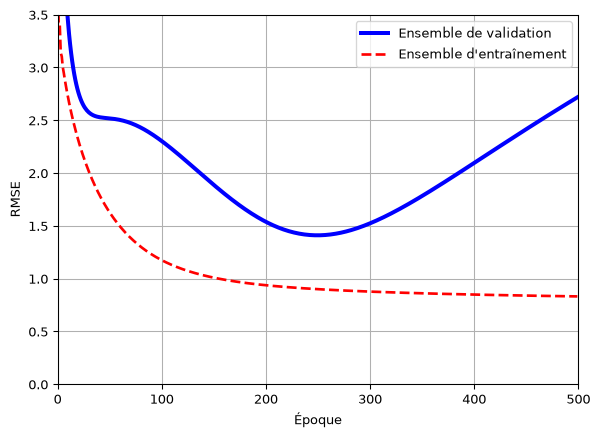

In [7]:
from copy import deepcopy
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import SGDRegressor

# Générer des données quadratiques bruitées et réserver des exemples de validation.
np.random.seed(42)
m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X ** 2 + X + 2 + np.random.randn(m, 1)
X_train, y_train = X[: m // 2], y[: m // 2, 0]
X_valid, y_valid = X[m // 2 :], y[m // 2 :, 0]

preprocessing = make_pipeline(PolynomialFeatures(degree=90, include_bias=False),
                              StandardScaler())
X_train_prep = preprocessing.fit_transform(X_train)
X_valid_prep = preprocessing.transform(X_valid)
sgd_reg = SGDRegressor(penalty=None, eta0=0.002, random_state=42)
n_epochs = 500
best_valid_rmse = float('inf')
train_errors, val_errors = [], []  # Code complémentaire pour la figure ci-dessous

for epoch in range(n_epochs):
    sgd_reg.partial_fit(X_train_prep, y_train)
    y_valid_predict = sgd_reg.predict(X_valid_prep)
    val_error = root_mean_squared_error(y_valid, y_valid_predict)
    if val_error < best_valid_rmse:
        best_valid_rmse = val_error
        best_model = deepcopy(sgd_reg)

    # Code complémentaire : calculer et conserver l'erreur d'entraînement pour la figure
    y_train_predict = sgd_reg.predict(X_train_prep)
    train_error = root_mean_squared_error(y_train, y_train_predict)
    val_errors.append(val_error)
    train_errors.append(train_error)

# Code complémentaire : produire et sauvegarder la figure 4–20
best_epoch = np.argmin(val_errors)
plt.plot(val_errors, "b-", linewidth=3, label="Ensemble de validation")
plt.plot(train_errors, "r--", linewidth=2, label="Ensemble d'entraînement")
plt.legend(loc="upper right")
plt.xlabel("Époque")
plt.ylabel("RMSE")
plt.axis([0, n_epochs, 0, 3.5])
plt.grid()
plt.show()

**Attribution** : Géron (2022), <a
href="https://github.com/ageron/handson-ml3/blob/main/04_training_linear_models.ipynb"
class="external" data-icon="true">04_training_linear_models.ipynb</a>.

Les choix de sortie et de perte définissaient ce que le modèle devait
prédire. Cette figure introduit un deuxième critère de progrès : la
performance sur des exemples qui ne servent pas aux mises à jour. La
plus faible erreur de validation désigne un point de sauvegarde plus
prometteur que la dernière époque, malgré la diminution continue de
l’erreur d’entraînement.

Un **point de sauvegarde** (*checkpoint*) est une copie des paramètres
du modèle à une étape donnée de l’entraînement. L’axe vertical utilise
la **racine de l’erreur quadratique moyenne (RMSE)**, soit la racine
carrée de la MSE introduite à la présentation 4; de faibles valeurs
indiquent de plus petites erreurs de prédiction, dans les unités
d’origine de la cible.

Le code exécute délibérément les 500 époques pour montrer les courbes
complètes et conserve le meilleur modèle sans l’indiquer sur le
graphique. Il illustre donc le choix d’un point de sauvegarde. Une
véritable procédure d’**arrêt précoce** (*early stopping*) interrompt
aussi les mises à jour lorsque son critère est satisfait. Les courbes de
validation peuvent fluctuer; une période de patience évite de s’arrêter
dès une petite détérioration. La courbe motive la règle d’arrêt
présentée ensuite.

## Pourquoi régulariser?

Une perte appropriée et des mises à jour efficaces peuvent quand même
produire du **surapprentissage** (*overfitting*).

- La **perte d’entraînement** mesure l’ajustement aux exemples fournis.
- La **performance de validation** aide à choisir des modèles qui
  généralisent.
- Une régularisation plus forte peut aussi causer du sous-apprentissage
  (*underfitting*).

L’écart entre les courbes d’entraînement et de validation explique
pourquoi réduire la perte d’entraînement n’est pas le seul objectif.
**La régularisation influence l’apprentissage pour favoriser des
solutions qui généralisent.** L’arrêt précoce contrôle la durée
d’ajustement des paramètres; les pénalités modifient l’objectif; le
dropout modifie les calculs d’entraînement. Leur utilité et leur
intensité doivent être évaluées sur les données de validation; le jeu de
test reste réservé à l’évaluation finale.

## Arrêt précoce

Comment transformer la courbe de validation en règle d’arrêt?

Surveiller une mesure de validation. Arrêter après un nombre choisi
d’époques sans amélioration significative, puis récupérer les meilleurs
paramètres.

Geoffrey Hinton parle d’un *« beautiful free lunch »*, un avantage
obtenu sans coût supplémentaire appréciable.

## Arrêter et restaurer les meilleurs paramètres

Pour un modèle Keras compilé, avec des données d’entraînement et de
validation préparées :

``` python
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)
    
model.fit(X_train, y_train, validation_data=(X_valid, y_valid),
          epochs=100, callbacks=[early_stopping])
```

Restaurer les meilleurs poids est un choix explicite : Keras ne le fait
pas par défaut. La patience contrôle le nombre d’époques sans
amélioration tolérées avant l’arrêt. On peut aussi fixer une
amélioration minimale avec `min_delta`. Ce choix doit utiliser la
validation, et non le test. Voir
<a href="https://keras.io/api/callbacks/early_stopping/"
class="external" data-icon="true">EarlyStopping dans Keras</a>.

## Ajouter une pénalité à la fonction objectif

Au-delà du moment d’arrêt, peut-on influencer les solutions privilégiées
par l’entraînement?

$$
J_{\mathrm{reg}}(W,b)=J_{\mathrm{data}}(W,b)+\Omega(W).
$$

La perte des données correspond à la tâche de prédiction. La pénalité
décourage certaines configurations des poids.

Le terme lié aux données peut être l’erreur quadratique moyenne,
l’erreur absolue moyenne, la BCE ou l’entropie croisée catégorielle. Par
exemple, la MAE moyenne $|\hat y_i-y_i|$ sur les exemples de régression.
Une pénalité s’ajoute séparément et est minimisée avec ce terme. Dans
cette présentation, les pénalités visent les poids, et non les biais,
sauf indication contraire.

## Comment mesurer la taille des poids?

Ces deux vecteurs de poids recevraient-ils la même pénalité?

| Poids   | Somme des valeurs absolues | Somme des carrés |
|:--------|---------------------------:|-----------------:|
| $(4,0)$ |                          4 |               16 |
| $(2,2)$ |                          4 |                8 |

L1 utilise $\|\mathbf w\|_1=\sum_j|w_j|$; la pénalité L2 habituelle
utilise $\|\mathbf w\|_2^2=\sum_j w_j^2$.

Les deux vecteurs ont la même somme de valeurs absolues, mais répartir
l’amplitude sur les deux composantes réduit la somme des carrés. Cette
comparaison explique comment les pénalités mesurent différemment la
taille des poids; elle ne prouve pas à elle seule que L1 produira un
modèle ajusté parcimonieux. Le terme de perte des données influence
aussi l’optimum.

La norme L1 est aussi appelée norme de Manhattan. La norme L2 ou
euclidienne est la racine carrée de la somme des carrés; la pénalité
habituelle de régularisation L2 utilise son carré, plutôt que la norme
elle-même.

Une **norme** attribue une longueur non négative à un vecteur.

Pour $p\geq1$, la **norme $\ell_p$** d’un vecteur
$\mathbf{z} = [z_1, z_2, \ldots, z_n]$ est définie par :

$$
  \|\mathbf{z}\|_p = \left( \sum_{i=1}^{n} |z_i|^p \right)^{1/p}
$$

Lorsque $p$ augmente, la norme $\ell_p$ accorde davantage d’importance
aux grandes valeurs de $z_i$ à cause de l’exponentiation.

Une **norme** est non négative et ne s’annule que pour le vecteur nul.
Multiplier un vecteur par un scalaire $c$ multiplie sa norme par $|c|$ :
$\|c\mathbf z\|=|c|\,\|\mathbf z\|$. L’**inégalité triangulaire**,
$\|\mathbf u+\mathbf v\|\leq\|\mathbf u\|+\|\mathbf v\|$, indique que la
longueur d’une somme ne dépasse pas la somme des longueurs.

## Régularisation $\ell_1$ et $\ell_2$

Soit $\mathbf w$ le vecteur de tous les poids. Les coefficients non
négatifs $\lambda_1$ et $\lambda_2$ contrôlent les pénalités; zéro
désactive le terme correspondant.

$$
J_{\mathrm{reg}}=J_{\mathrm{data}}(W,b)
+\lambda_1\|\mathbf w\|_1
+\frac{\lambda_2}{2}\|\mathbf w\|_2^2.
$$

Le terme L1 additionne les valeurs absolues des poids. La pénalité L2
habituelle additionne leurs carrés : elle utilise le carré de la norme
euclidienne ou de Frobenius, plutôt que la norme elle-même. Le facteur
un demi est une convention qui donne la dérivée $\lambda_2 W$, comme
dans `SimpleMLP` plus loin. Les conventions de coefficients diffèrent
selon les bibliothèques.

## Réduction des coefficients et parcimonie

- **Régularisation $\ell_1$** :
  - Favorise la **parcimonie** (*sparsity*); des solveurs appropriés
    peuvent fixer des coefficients exactement à zéro.
  - Peut permettre la **sélection d’attributs**, surtout dans les
    modèles linéaires.
- **Régularisation $\ell_2$** :
  - Favorise des **poids petits et répartis** pour la stabilité.
  - Réduit collectivement les poids et conserve habituellement une
    solution dense.

Exemple avancé, en anglais : [Régularisation avec attributs corrélés
](kong_and_yu-2018.qmd).

La **réduction des coefficients** (*shrinkage*) désigne la réduction de
leur amplitude sous l’effet de la pénalité. Un **vecteur de coefficients
parcimonieux** (*sparse coefficient vector*) contient de nombreux zéros
exacts; un vecteur **dense** en contient peu ou aucun. La **sélection
d’attributs** (*feature selection*) consiste à conserver un
sous-ensemble des attributs d’entrée d’origine. Dans un modèle linéaire,
un coefficient nul supprime le terme de cet attribut dans la prédiction.
L’effet du sous-ensemble choisi sur la prédiction doit être évalué
séparément. Des **attributs corrélés** varient ensemble; le
chevauchement de leur information peut influencer les coefficients
choisis et la répartition des poids.

## Quels coefficients disparaissent vraiment?

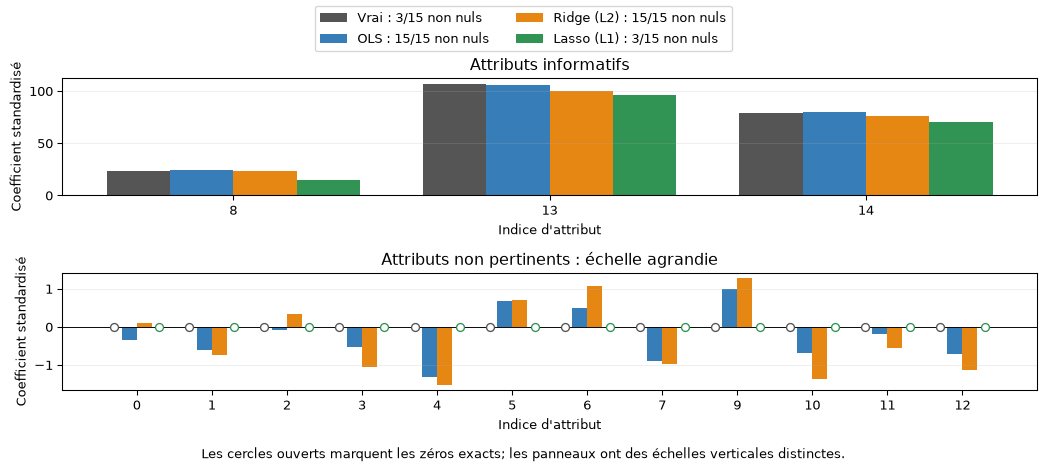

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler

X, y, true_coef = make_regression(n_samples=200, n_features=15, n_informative=3,
                                 noise=10.0, coef=True, random_state=42)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Exprimer les coefficients connus dans les mêmes coordonnées que les modèles ajustés.
true_coef_scaled = true_coef * scaler.scale_
coefficient_models = {
    'OLS': LinearRegression().fit(X_scaled, y),
    'Ridge (L2)': Ridge(alpha=10.0).fit(X_scaled, y),
    'Lasso (L1)': Lasso(alpha=10.0).fit(X_scaled, y)
}

series = [('Vrai', true_coef_scaled)] + [
    (name, fitted.coef_) for name, fitted in coefficient_models.items()
]
colors = ['#555555', '#377eb8', '#e68613', '#319354']
groups = [
    (true_coef != 0, 'Attributs informatifs'),
    (true_coef == 0, 'Attributs non pertinents : échelle agrandie')
]
fig, axes = plt.subplots(2, 1, figsize=(11, 4.8))
for ax, (mask, title) in zip(axes, groups):
    feature_indices = np.flatnonzero(mask)
    positions = np.arange(len(feature_indices))
    for offset, ((name, values), color) in enumerate(zip(series, colors)):
        x_positions = positions + (offset-1.5)*0.2
        nonzero = np.count_nonzero(values)
        ax.bar(x_positions, values[mask], width=0.2, color=color,
               label=f'{name} : {nonzero}/15 non nuls')
        zeros = values[mask] == 0
        ax.scatter(x_positions[zeros], values[mask][zeros], s=35,
                   facecolors='white', edgecolors=color, zorder=4)
    ax.set(xticks=positions, xticklabels=feature_indices, xlabel="Indice d'attribut",
           ylabel='Coefficient standardisé', title=title)
    ax.axhline(0, color='black', linewidth=0.7)
    ax.grid(axis='y', alpha=0.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2)
fig.text(0.5, 0.01, 'Les cercles ouverts marquent les zéros exacts; les panneaux ont des échelles verticales distinctes.',
         ha='center')
fig.tight_layout(rect=(0, 0.035, 1, 0.91))
plt.show()

[Régularisation : réduction des coefficients et parcimonie
](regularization.qmd).

Cet exemple de régression linéaire isole l’effet de la pénalité. Quinze
prédicteurs sont générés, mais seuls trois ont un vrai coefficient non
nul. Les attributs informatifs et non pertinents utilisent des échelles
verticales distinctes pour rendre visibles les petites estimations non
nulles. Les cercles ouverts marquent les zéros exacts. Avec ces réglages
fixes, OLS et Ridge conservent quinze coefficients non nuls; Lasso en
conserve trois, soit 80 % de zéros exacts, et identifie les prédicteurs
informatifs de ce jeu de données.

Les **moindres carrés ordinaires (OLS)** ajustent un modèle linéaire en
minimisant la **somme des carrés des résidus (RSS)**. Un résidu est la
cible observée moins sa prédiction; la RSS additionne les résidus au
carré sur les exemples. C’est la fonction objectif des moindres carrés
de la présentation 4, sous son nom statistique. **Ridge** ajoute une
pénalité L2 au carré sur les coefficients; **Lasso** ajoute une pénalité
L1. Voir les
<a href="https://scikit-learn.org/stable/modules/linear_model.html"
class="external" data-icon="true">définitions des modèles linéaires de
scikit-learn</a>.

OLS sert de référence sans régularisation. Des valeurs numériques égales
d’alpha n’impliquent pas des pénalités d’intensité égale. Ridge dans
scikit-learn minimise la RSS plus alpha fois le carré de la norme L2,
tandis que Lasso divise la RSS par $2N$ avant d’ajouter sa pénalité L1.
Ces réglages servent une comparaison qualitative, et non une comparaison
à intensité égale.

Les modèles utilisent des **attributs** (*features*) standardisés :
chacun est centré selon sa moyenne d’entraînement puis divisé par son
écart-type d’entraînement. Cette **standardisation** (*standardization*)
explicite l’hypothèse d’échelle. Les vrais coefficients sont exprimés
dans les mêmes coordonnées. Modifier les unités d’un attribut change le
coefficient nécessaire pour préserver une prédiction, et donc sa
pénalité. Les attributs générés ont déjà des échelles similaires, d’où
une faible différence numérique ici. Pour une évaluation sur des données
réservées, ajuster le standardiseur uniquement sur l’entraînement. Le
carnet explique la conversion des coefficients et affiche tous les
décomptes.

## Ajouter L2 dans Keras

``` python
import keras

l2 = 0.001
regularizer = keras.regularizers.L2(l2 / 2)
dense = keras.layers.Dense(50, kernel_regularizer=regularizer)
```

Pour une couche Dense, le **kernel** est sa matrice de poids. Appliquer
la pénalité à chaque couche dont les poids doivent être pénalisés.

Keras `L2(c)` ajoute $c\sum w^2$; sa dérivée est donc $2cW$. Utiliser
`c=l2/2` respecte la convention $\lambda/2$ de cette présentation et de
`SimpleMLP`. Un coefficient numérique de pénalité ne prend son sens
qu’avec la définition de la bibliothèque. `kernel_regularizer` ne
pénalise pas le biais; c’est une option distincte. Voir les
<a href="https://keras.io/api/layers/regularizers/" class="external"
data-icon="true">régulariseurs de Keras</a>.

## Et si certaines activations étaient indisponibles?

Supprimer temporairement des activations cachées pourrait-il aider un
modèle à généraliser?

- Le **dropout** met aléatoirement certaines activations à zéro pendant
  l’entraînement.
- **Objectif :** réduire le surapprentissage en décourageant la
  dépendance à la disponibilité permanente d’unités particulières.

Hinton et al. (2012)

Supposons qu’une prédiction dépende fortement d’une unité cachée.
Lorsque le dropout met son activation à zéro pour un exemple
d’entraînement, sa contribution devient indisponible. Les autres unités
doivent fournir l’information utilisée pour cette prédiction. Répéter ce
processus en supprimant différentes activations encourage des
prédictions utiles sans dépendre excessivement de combinaisons
particulières d’unités (Hinton et al. 2012).

L’objectif est une meilleure performance sur de nouveaux exemples.
L’entraînement peut devenir plus difficile et sa perte peut augmenter;
la performance de validation détermine si le dropout améliore la
généralisation. Un dropout excessif peut causer du sous-apprentissage.

Les pénalités sur les poids modifient l’objectif en ajoutant un terme
qui dépend des poids. Le dropout modifie le calcul d’entraînement. Les
mêmes paramètres sont partagés entre ces calculs, et différentes
activations sont choisies aléatoirement pour être supprimées au fil de
l’entraînement. Les unités et leurs poids restent dans le modèle; les
valeurs des activations sont temporairement modifiées.

## Pourquoi redimensionner les activations conservées?

Une activation vaut 4 avant le dropout et est supprimée la moitié du
temps. Quelle est sa valeur moyenne après le dropout?

| Résultat                       | Sans mise à l’échelle | Avec mise à l’échelle |
|:-------------------------------|----------------------:|----------------------:|
| Supprimée (la moitié du temps) |                     0 |                     0 |
| Conservée (la moitié du temps) |                     4 |                     8 |
| **Moyenne**                    |                 **2** |                 **4** |

Pour un taux de dropout $p$, diviser chaque activation conservée par
$1-p$.

Le **taux de dropout** $p$ est la probabilité de mettre une activation à
zéro pendant l’entraînement, avec $0\leq p<1$. L’activation est
conservée avec probabilité $1-p$. Les deux résultats du tableau sont
équiprobables, puisque $p=0.5$.

Sans mise à l’échelle, la moyenne est $(0+4)/2=2$. Diviser les
activations conservées par $1-p=0.5$ les double et donne une moyenne de
$(0+8)/2=4$. Cela compense les activations supprimées. Plus
généralement, une activation d’origine $a$ devient zéro si elle est
supprimée et $a/(1-p)$ si elle est conservée.

Cette moyenne décrit de nombreuses répétitions avec la même activation
d’origine; un seul calcul produit ici soit 0, soit 8. La mise à
l’échelle garde une amplitude moyenne comparable à l’utilisation
habituelle, tandis que chaque calcul comporte encore des activations
manquantes. Cette variation fournit l’effet de régularisation. Elle ne
garantit pas que la prédiction finale du réseau soit préservée en
moyenne, puisque les couches suivantes peuvent être non linéaires.

Avec les réglages habituels de Keras, les choix aléatoires se font
séparément pour chaque exemple et chaque activation. Une unité peut donc
être supprimée pour certains exemples et conservée pour d’autres dans le
même lot. Pour un exemple où une activation est supprimée, aucun
gradient ne la traverse; d’autres exemples peuvent toujours contribuer
aux mises à jour des paramètres de l’unité.

## Entraînement et inférence

Faut-il encore supprimer des activations lorsque le modèle entraîné fait
des prédictions?

| Mode | Supprimer des activations? | Redimensionner les activations conservées? |
|:-----------------------|:-----------------------|:-----------------------|
| Entraînement | Oui, au taux $p$ | Oui, par $1/(1-p)$ |
| Inférence | Non | Non |

Pendant l’inférence habituelle, toutes les unités sont disponibles et le
dropout laisse les activations inchangées. Les activations conservées
ayant été redimensionnées pendant l’entraînement, aucune mise à
l’échelle supplémentaire liée au dropout n’est nécessaire à l’inférence.

Keras gère automatiquement cette distinction : le dropout est actif pour
l’entraînement dans `model.fit` et inactif pour la validation,
`model.evaluate` et `model.predict`. La validation mesure donc le modèle
dans ses conditions habituelles de prédiction. Voir
<a href="https://keras.io/api/layers/regularization_layers/dropout/"
class="external" data-icon="true">Dropout dans Keras</a>.

## Dropout dans le modèle Fashion-MNIST

``` python
import keras
from keras.models import Sequential
from keras.layers import InputLayer, Dropout, Flatten, Dense

model = keras.Sequential([
    InputLayer(shape=[28, 28]),
    Flatten(),
    Dropout(rate=0.2),
    Dense(300, activation="relu"),
    Dropout(rate=0.2),
    Dense(100, activation="relu"),
    Dropout(rate=0.2),
    Dense(10, activation="softmax")
])
```

Ajout de couches `Dropout` au modèle Fashion-MNIST de la présentation
11. Un taux de 0.2 supprime chaque activation avec une probabilité de 20
% pendant l’entraînement.

Chaque couche `Dropout` agit sur les activations fournies par la couche
précédente. Après `Flatten`, il s’agit des valeurs des pixels d’entrée;
après une couche `Dense`, des activations des unités cachées. Une couche
`Dropout` n’ajoute aucun poids entraînable. La rétropropagation calcule
toujours les gradients des couches Dense voisines et l’optimiseur met à
jour leurs paramètres comme précédemment.

Le taux est une probabilité par activation; il n’est pas nécessaire de
supprimer exactement 20 % des activations pour chaque exemple. Avec
`rate=0.2`, chaque activation conservée est divisée par 0.8, donc
multipliée par 1.25, pendant l’entraînement. Le taux peut varier selon
la couche.

Cet exemple montre où insérer le dropout dans une architecture
familière. Pour savoir s’il améliore les prédictions, comparer la
performance de validation à celle d’un modèle autrement comparable sans
dropout. Choisir les taux à partir de la validation; un dropout trop
fort peut compliquer l’apprentissage de régularités utiles.

# Poursuite de l’apprentissage et rétention

## Inférence et poursuite de l’apprentissage

Le modèle fonctionne bien. Peut-il continuer à apprendre de nouveaux
exemples sans perdre ses capacités antérieures?

- **Inférence :** calculer des prédictions avec les paramètres actuels.
- **Poursuite de l’apprentissage :** mettre à jour les paramètres par un
  processus d’entraînement explicite.
- Évaluer les mises à jour sur les **capacités antérieures** autant que
  sur les nouvelles données.

Un modèle ne modifie habituellement pas ses poids simplement parce qu’il
reçoit une nouvelle demande de prédiction. L’apprentissage exige une
rétroaction, un objectif et une procédure de mise à jour. Une chaîne
d’entraînement peut produire périodiquement une nouvelle version du
modèle ou le mettre à jour continuellement.

L’**apprentissage en ligne** (*online learning*) met à jour un modèle
progressivement à mesure que de nouvelles observations arrivent, au lieu
de s’appuyer uniquement sur un jeu fixe et une phase distincte de
réentraînement. L’**ajustement fin** (*fine-tuning*) est la poursuite de
l’entraînement d’un modèle déjà entraîné. L’**apprentissage continu**
(*continual learning*) étudie l’apprentissage sur des données ou des
tâches successives tout en conservant les capacités antérieures. Ces
termes décrivent des processus d’apprentissage; l’inférence habituelle
calcule les sorties sans effectuer ces mises à jour.

Des réseaux en production peuvent apprendre en ligne; des systèmes de
recommandation en temps réel comme
<a href="https://arxiv.org/abs/2209.07663" class="external"
data-icon="true">Monolith</a> en sont des exemples. La distinction porte
sur l’inférence et le processus délibéré de mise à jour, et non sur une
interdiction générale de l’entraînement en ligne. Voir la <a
href="https://developers.google.com/machine-learning/crash-course/production-ml-systems/static-vs-dynamic-training"
class="external" data-icon="true">discussion de Google sur
l’entraînement statique et dynamique</a>.

## Apprendre B préservera-t-il la capacité A?

| Phase | Données d’entraînement | Évaluation ensuite |
|:------|:-----------------------|:-------------------|
| A     | Chiffres MNIST 0–4     | Les deux groupes   |
| B     | Chiffres MNIST 5–9     | Les deux groupes   |

Conserver les dix mêmes classes de sortie et les étiquettes d’origine
pendant toute l’expérience.

Après la phase B, que prévoyez-vous pour l’exactitude sur les chiffres
0–4?

Le modèle s’entraîne d’abord sur les chiffres 0–4, puis poursuit
l’entraînement sur les chiffres 5–9. La dimension de sortie et le sens
de chaque étiquette restent fixes. La seconde phase vérifie donc si
l’apprentissage de nouvelles classes préserve les prédictions
antérieures sans fournir d’anciens exemples supplémentaires. Cela
diffère de l’inférence habituelle, qui laisse les paramètres inchangés.

**MNIST** contient des images de chiffres manuscrits de 0 à 9, en
niveaux de gris et de 28 par 28 pixels. Il diffère de Fashion-MNIST, le
jeu d’images de vêtements utilisé plus tôt. Une configuration
d’**apprentissage incrémental par classes** (*class-incremental
learning*) introduit des classes par phases successives et évalue la
reconnaissance de toutes les classes rencontrées jusque-là; après la
phase B, il s’agit ici des dix chiffres.

Cette configuration est incrémentale par classes : les dix classes sont
disponibles pour chaque prédiction. Restreindre les prédictions au
groupe de classes connu de la tâche répondrait à une autre question,
plus facile. Voir
<a href="https://arxiv.org/abs/1904.07734" class="external"
data-icon="true">van de Ven et Tolias (2019)</a>.

## Que sont devenues les classes antérieures?

Exactitude au test dans l’exécution MNIST consignée :

| Point de sauvegarde | Chiffres 0–4 (A) | Chiffres 5–9 (B) |
|:--------------------|-----------------:|-----------------:|
| Après A             |           97.0 % |            0.0 % |
| Après B seulement   |            2.3 % |           93.8 % |

Quels exemples étaient absents de la phase B? Comment réintroduire une
partie de cette information?

**Oubli catastrophique** (*catastrophic forgetting*) : poursuivre
l’entraînement peut réduire fortement la performance sur des tâches
antérieures.

Ces exactitudes au test ont été mesurées en fin de phase dans
l’exécution consignée du carnet complémentaire; ce ne sont pas les
exactitudes de validation tracées à la diapositive suivante. Chaque
évaluation considère les dix classes de sortie. Les valeurs exactes
peuvent varier selon le moteur de calcul et le matériel, mais cette
exécution illustre une perte prononcée d’exactitude sur les anciennes
classes malgré l’apprentissage réussi des nouvelles.

Le deuxième objectif d’entraînement ne contient aucun exemple exigeant
que les prédictions antérieures restent correctes. Ses mises à jour
peuvent perturber les représentations partagées et favoriser les classes
récentes. Les images et les étiquettes du test d’origine ne changent
pas. Une baisse ne prouve pas que toutes les anciennes représentations
utiles ont été effacées.

L’absence d’anciens exemples suggère une intervention directe :
conserver une petite mémoire et mélanger des exemples antérieurs aux
mises à jour suivantes. Cette proposition est testée ensuite avec les
mêmes paramètres appris au départ et le même nombre de mises à jour pour
les deux branches de la phase B.

## Une petite mémoire pourrait-elle aider?

Que changerait l’inclusion d’anciens exemples dans certaines mises à
jour de la phase B?

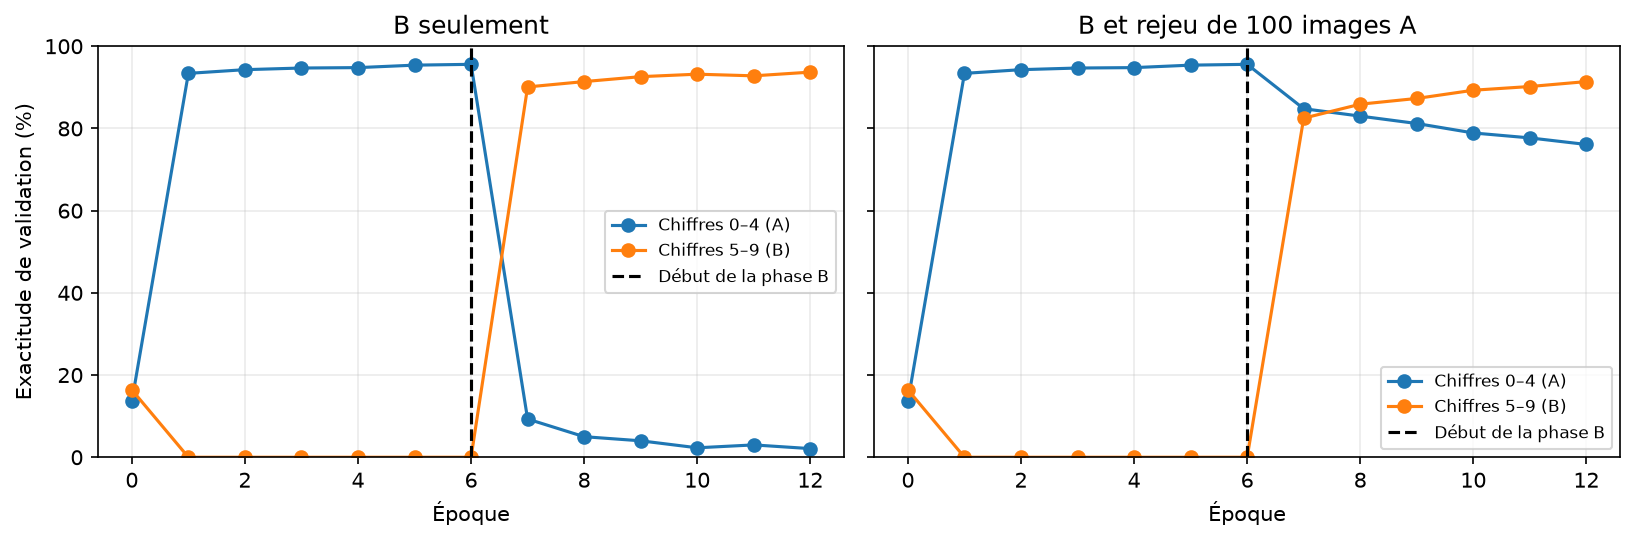

[Oubli catastrophique sur MNIST ](catastrophic_forgetting.qmd) :
reproduire l’expérience et examiner les résultats de test en fin de
phase.

Les deux panneaux partagent le même historique de phase A et commencent
la phase B avec des paramètres appris identiques. Les deux branches de
phase B ont la même taille de lot et le même nombre de mises à jour. La
seconde utilise la moitié de chaque lot pour réutiliser des exemples
issus d’une mémoire équilibrée de 100 anciennes images d’entraînement;
cela modifie le mélange des données dans ce budget fixe.

Une **mémoire équilibrée** conserve le même nombre d’exemples de chaque
ancienne classe : ici, 20 images de chacune des cinq classes A. La
**rétention** est le maintien de la performance sur les anciennes
données après un entraînement ultérieur.

Cette réutilisation d’anciens exemples conservés en mémoire constitue le
**rejeu d’exemples** (*replay*). Dans cette exécution, elle améliore
nettement la rétention tout en permettant l’apprentissage des nouvelles
classes; elle ne préserve pas parfaitement l’exactitude antérieure.

La figure utilise l’exactitude de validation pour suivre les deux
capacités. Le carnet consigne des mesures de fin de phase prédéfinies
sur le jeu de test officiel de MNIST et rapporte séparément la baisse
d’exactitude sur A. La seule performance sur la nouvelle tâche
masquerait le problème de rétention.

Le rejeu d’exemples réintroduit un objectif sur les anciennes données.
La régularisation L2 habituelle centrée en zéro décourage les grands
poids; elle ne préserve pas explicitement les prédictions antérieures.
Pour approfondir, la
<a href="https://arxiv.org/abs/1612.00796" class="external"
data-icon="true">consolidation élastique des poids (EWC)</a> pénalise
les écarts par rapport aux paramètres appris précédemment, avec des
pénalités plus fortes pour les paramètres jugés importants aux tâches
antérieures. L’oubli catastrophique concerne l’ajustement fin périodique
par lots autant que les mises à jour en ligne.

# Épilogue

## Résumé

- **Optimisation :** un gradient local correct ne garantit pas un
  entraînement réussi.
- **Propagation des gradients :** activation, initialisation, écrêtage
  et taille des mises à jour répondent à différentes difficultés.
- **Sorties et pertes :** choisir ensemble la représentation de sortie
  et l’objectif; distinguer logits, probabilités et étiquettes de
  classe.
- **Généralisation :** L1/L2, dropout et arrêt précoce peuvent aider;
  évaluer leur intensité avec la validation.
- **Rétention :** poursuivre l’entraînement peut causer de l’oubli;
  évaluer les acquis et envisager le rejeu d’exemples.
- **Implémentation :** `SimpleMLP` conserve la structure de
  rétropropagation tout en ajoutant des choix d’entraînement.

## Prochaine présentation

Pour les images, une architecture pourrait-elle exploiter la structure
spatiale plutôt que traiter toutes les connexions d’entrée de la même
manière?

- Les réseaux de neurones convolutifs répondent à cette question
  d’architecture.

## Références

Géron, Aurélien. 2022. *Hands-on Machine Learning with Scikit-Learn,
Keras, and TensorFlow*. 3ᵉ éd. O’Reilly Media, Inc.

Glorot, Xavier, et Yoshua Bengio. 2010. « Understanding the difficulty
of training deep feedforward neural networks ». In *Proceedings of the
Thirteenth International Conference on Artificial Intelligence and
Statistics*, édité par Yee Whye Teh et Mike Titterington, vol. 9.
Proceedings of Machine Learning Research. PMLR.
<https://proceedings.mlr.press/v9/glorot10a.html>.

Hinton, Geoffrey E., Nitish Srivastava, Alex Krizhevsky, Ilya Sutskever,
et Ruslan Salakhutdinov. 2012. « Improving neural networks by preventing
co-adaptation of feature detectors ». *CoRR* abs/1207.0580.
<http://arxiv.org/abs/1207.0580>.

Krizhevsky, Alex, Ilya Sutskever, et Geoffrey E Hinton. 2012. « ImageNet
Classification with Deep Convolutional Neural Networks ». In *Advances
in Neural Information Processing Systems*, édité par F. Pereira, C. J.
Burges, L. Bottou, et K. Q. Weinberger, vol. 25. Curran Associates, Inc.
<https://proceedings.neurips.cc/paper_files/paper/2012/file/c399862d3b9d6b76c8436e924a68c45b-Paper.pdf>.

LeCun, Yann, Yoshua Bengio, et Geoffrey Hinton. 2015. « Deep learning ».
*Nature* 521 (7553): 436‑44. <https://doi.org/10.1038/nature14539>.

Rumelhart, David E., Geoffrey E. Hinton, et Ronald J. Williams. 1986.
« Learning representations by back-propagating errors ». *Nature* 323
(6088): 533‑36. <https://doi.org/10.1038/323533a0>.

Russell, Stuart, et Peter Norvig. 2020. *Artificial Intelligence: A
Modern Approach*. 4ᵉ éd. Pearson. <http://aima.cs.berkeley.edu/>.

# Annexe : étendre l’implémentation

## De SimplerMLP à SimpleMLP

Quels choix exigent de modifier le code et où interviennent-ils dans les
calculs?

| Composante | `SimplerMLP` (présentation 13) | `SimpleMLP` |
|:-----------------------|:-----------------------|:-----------------------|
| Activation cachée | Sigmoïde | Sigmoïde ou ReLU |
| Initialisation | Glorot | He pour ReLU; Glorot pour sigmoïde |
| Sortie | Probabilité sigmoïde | Probabilité sigmoïde |
| Taux d’apprentissage | Constant | Constant ou décroissance exponentielle |
| Perte | BCE moyenne | BCE moyenne et L2 facultative |
| Dropout | Aucun | Facultatif; même taux pour toutes les couches cachées |
| Ordre des exemples | Mélange à chaque époque | Mélange facultatif, activé par défaut |
| Valeurs conservées | Activations et préactivations | Aussi les masques de dropout redimensionnés |
| API de prédiction et d’entraînement | Mêmes méthodes | Mêmes méthodes |

La nouvelle classe étend l’implémentation précédente tout en conservant
sa structure de calcul. Les deux sont des classifieurs binaires à sortie
sigmoïde unique. Changer l’activation cachée exige une dérivée locale
correspondante et une initialisation appropriée, mais la règle de
dérivation en chaîne et la boucle arrière restent les mêmes.

Chaque ajout répond à une difficulté abordée plus tôt : les fonctions
auxiliaires d’activation choisissent les pentes locales,
l’initialisation contrôle l’échelle de départ des poids, L2 ajoute une
pénalité, le dropout modifie le calcul d’entraînement et un calendrier
fait évoluer la taille des mises à jour selon les époques. Les
activations et préactivations conservées, l’orientation des matrices et
la collecte des gradients restent cohérentes avec la présentation 13. Le
dropout ajoute des masques redimensionnés conservés en mémoire et un
facteur correspondant au passage arrière.

Cette classe implémente une sélection des choix de la présentation. Elle
conserve la BCE binaire et n’implémente pas softmax multiclasse, l’arrêt
précoce ou l’écrêtage des gradients. Les exemples Keras et les carnets
illustrent ces autres outils. Ces portées distinctes gardent
l’implémentation NumPy lisible tout en reliant les concepts au code.

Les réglages `hidden_activation="sigmoid"`, `l2=0.0`, `lr_decay=None` et
`dropout_rate=0.0` redonnent les calculs de `SimplerMLP`. Avec la même
graine et `shuffle=True` par défaut, les deux classes initialisent et
mélangent les données de manière identique. `SimpleMLP` ajoute l’option
`shuffle` à `train` : `shuffle=False` conserve l’ordre fourni des
exemples d’une époque à l’autre. Cela est utile si l’entraînement dépend
de cet ordre, comme expliqué dans la présentation 13; cela ne transforme
pas à soi seul ce classifieur à propagation avant en modèle de
séquences. La définition complète et des extraits ciblés suivent et
restent disponibles pour l’exécution autonome du carnet.

## SimpleMLP

In [9]:
import numpy as np

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_prime(z):
    a = sigmoid(z)
    return a * (1.0 - a)

def bce_loss(y_true, y_prob, eps=1e-9):
    """Entropie croisée binaire moyennée sur les exemples."""
    p = np.clip(y_prob, eps, 1 - eps)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def xavier_init(rng, fan_in, fan_out):
    std = np.sqrt(2.0 / (fan_in + fan_out))
    return rng.normal(0.0, std, size=(fan_in, fan_out))

def relu(z):
    return np.maximum(0.0, z)

def relu_prime(z):
    return (z > 0).astype(float)

def he_init(rng, fan_in, fan_out):
    std = np.sqrt(2.0 / fan_in)
    return rng.normal(0.0, std, size=(fan_in, fan_out))

class SimpleMLP:
    """MLP binaire avec choix d'activation cachée, L2, dropout et décroissance du taux."""

    def __init__(self, layer_sizes, lr=0.1, seed=None, l2=0.0,
                 hidden_activation="relu", lr_decay=None, dropout_rate=0.0):
        self.sizes = list(layer_sizes)
        self.lr = float(lr)
        self.base_lr = float(lr)
        self.l2 = float(l2)
        self.hidden_activation = hidden_activation
        self.lr_decay = lr_decay
        self.dropout_rate = float(dropout_rate)
        self.rng = np.random.default_rng(seed)

        self.W = []
        L = len(self.sizes) - 1
        for l, (din, dout) in enumerate(zip(self.sizes[:-1], self.sizes[1:]), start=1):
            if l < L and self.hidden_activation == "relu":
                Wk = he_init(self.rng, din, dout)
            else:
                Wk = xavier_init(self.rng, din, dout)
            self.W.append(Wk)
        self.b = [np.zeros(dout) for dout in self.sizes[1:]]

    def _act(self, z, last=False):
        if last:
            return sigmoid(z)
        return relu(z) if self.hidden_activation == "relu" else sigmoid(z)

    def _act_prime(self, z, last=False):
        if last:
            return sigmoid_prime(z)
        return relu_prime(z) if self.hidden_activation == "relu" else sigmoid_prime(z)

    def forward(self, X):
        a = X
        L = len(self.W)
        for l, (W, b) in enumerate(zip(self.W, self.b), start=1):
            a = self._act(a @ W + b, last=(l == L))
        return a.ravel()

    def predict_proba(self, X):
        return self.forward(X)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def loss(self, X, y):
        """Rapporter la BCE moyenne et L2, sans dropout."""
        p = self.predict_proba(X)
        base = bce_loss(y, p)
        if self.l2 > 0:
            base += 0.5 * self.l2 * sum((W ** 2).sum() for W in self.W)
        return base

    def _forward_full(self, X):
        a = X
        activations = [a]
        zs = []
        dropout_masks = []
        L = len(self.W)
        for l, (W, b) in enumerate(zip(self.W, self.b), start=1):
            z = a @ W + b
            a = self._act(z, last=(l == L))

            # Masque identité pour la sortie et lorsque le dropout est désactivé.
            mask = np.ones_like(a)
            if l < L and self.dropout_rate > 0:
                keep_prob = 1.0 - self.dropout_rate
                mask = (self.rng.random(a.shape) >= self.dropout_rate) / keep_prob
                a = a * mask

            zs.append(z)
            activations.append(a)
            dropout_masks.append(mask)
        return activations, zs, dropout_masks

    def train(self, X, y, epochs=30, batch_size=None, verbose=True, shuffle=True):
        """X : (N, d), y : (N,); batch_size=None utilise toutes les données."""
        N = X.shape[0]
        idx = np.arange(N)
        B = N if batch_size is None else int(batch_size)

        for ep in range(1, epochs + 1):
            if shuffle:
                self.rng.shuffle(idx)
            if self.lr_decay is not None:
                self.lr = self.base_lr * self.lr_decay ** (ep - 1)

            base_loss = self.loss(X, y)

            for start in range(0, N, B):
                sl = idx[start:start + B]
                Xb = X[sl]
                yb = y[sl].reshape(-1, 1)
                Bsz = Xb.shape[0]

                activations, zs, dropout_masks = self._forward_full(Xb)
                A_L = activations[-1]

                # Chaque ligne est la sensibilité aux préactivations pour un exemple.
                delta = A_L - yb
                grads_W = [None] * len(self.W)
                grads_b = [None] * len(self.b)

                # Moyenner une seule fois les gradients des paramètres sur les exemples.
                grads_W[-1] = activations[-2].T @ delta / Bsz
                grads_b[-1] = delta.mean(axis=0)

                for k in range(len(self.W) - 2, -1, -1):
                    z = zs[k]
                    d_act = self._act_prime(z, last=False)
                    delta = delta @ self.W[k + 1].T
                    delta = delta * dropout_masks[k]
                    delta = delta * d_act
                    grads_W[k] = activations[k].T @ delta / Bsz
                    grads_b[k] = delta.mean(axis=0)

                if self.l2 > 0:
                    for k in range(len(self.W)):
                        grads_W[k] += self.l2 * self.W[k]

                # Tous les gradients utilisent les poids du même passage avant.
                for k in range(len(self.W)):
                    self.W[k] -= self.lr * grads_W[k]
                    self.b[k] -= self.lr * grads_b[k]

            new_loss = self.loss(X, y)
            if verbose:
                print(f"Époque {ep:3d} | perte {base_loss:.5f} -> {new_loss:.5f} | taux={self.lr:.4f}")

## Choisir les activations cachées

Si l’activation du passage avant change, quelle dérivée locale le
passage arrière doit-il utiliser?

``` python
    def _act(self, z, last=False):
        if last:
            return sigmoid(z)
        return relu(z) if self.hidden_activation == "relu" else sigmoid(z)

    def _act_prime(self, z, last=False):
        if last:
            return sigmoid_prime(z)
        return relu_prime(z) if self.hidden_activation == "relu" else sigmoid_prime(z)
```

La sortie reste sigmoïde pour la classification binaire. ReLU n’est
proposée que pour les unités cachées. La présentation 13 appelait
directement `sigmoid` et `sigmoid_prime`. Ici, `_act` et `_act_prime`
choisissent l’activation et sa dérivée, tandis que `last` indique la
couche de sortie. Les passages avant et avant avec valeurs conservées
appellent maintenant `_act`; la boucle arrière appelle `_act_prime`. La
multiplication par `W_next.T` et la moyenne sur les exemples restent les
mêmes.

## L2 dans l’objectif et le gradient

$$
J_{\mathrm{reg}}=J_{\mathrm{BCE}}+
\frac{\lambda}{2}\sum_{l=1}^{L}\|W^{(l)}\|_F^2.
$$

``` python
base += 0.5 * self.l2 * sum((W ** 2).sum() for W in self.W)

# Après le calcul des gradients moyens de la perte des données :
grads_W[k] += self.l2 * self.W[k]
```

Le coefficient `l2` est $\lambda$. La perte des données est moyennée sur
les exemples; la pénalité s’ajoute séparément, sans autre division par
la taille du jeu ou du mini-lot. Sa dérivée est donc $\lambda W$ dans
chaque lot. Cela assure la cohérence entre le terme L2 de la perte
rapportée et sa contribution aux mises à jour. Les biais ne sont pas
pénalisés.

Le carré de la norme de Frobenius est simplement la somme des carrés des
entrées d’une matrice de poids. Ce code implémente la pénalité L2 au
carré introduite plus tôt. L2 décourage les grands poids; elle ne change
pas les dérivées locales d’activation et ne répare pas directement la
propagation des gradients.

## Dropout aux passages avant et arrière

Quelle dérivée locale supplémentaire le dropout introduit-il?

Pendant le passage avant d’entraînement, pour une couche cachée :

``` python
keep_prob = 1.0 - self.dropout_rate
mask = (self.rng.random(a.shape) >= self.dropout_rate) / keep_prob
a = a * mask
```

Pendant le passage arrière, réutiliser le masque redimensionné conservé
:

``` python
delta = delta * dropout_masks[k]
```

Activer avec `dropout_rate=0.2`; la valeur par défaut zéro désactive le
dropout.

`SimpleMLP` utilise un même taux pour **toutes les couches cachées**.
Keras permet de placer des couches `Dropout` individuellement et de
choisir leurs taux séparément.

Pour un taux $0\leq p<1$, chaque entrée du masque vaut zéro avec
probabilité $p$, et $1/(1-p)$ sinon. Sa forme correspond au tableau
d’activations du lot; les choix se font donc séparément pour chaque
exemple et unité cachée. Le masque est échantillonné une fois au passage
avant d’entraînement et conservé pour son passage arrière. Un nouveau
masque est échantillonné au passage avant d’entraînement suivant.

Pour un masque échantillonné fixé, $\widetilde a=ma$ possède une dérivée
locale $m$ par rapport à $a$. Le passage arrière multiplie donc par le
même masque redimensionné. Une activation supprimée bloque le gradient
de ce chemin; une activation conservée transmet aussi le facteur de mise
à l’échelle. La dérivée d’activation est évaluée à la préactivation
`zs[k]` conservée avant le dropout. En particulier, il ne faut pas
calculer la dérivée sigmoïde à partir d’une activation déjà masquée et
redimensionnée.

La liste `activations` conserve les valeurs réellement transmises à la
couche suivante, y compris l’effet du dropout. Les gradients des
paramètres utilisent ces mêmes valeurs. La sortie n’est pas supprimée;
son signal d’erreur sigmoïde/BCE reste donc `A_L - yb`.

Cette implémentation applique le même taux à chaque couche cachée. Elle
n’applique pas de dropout aux entrées brutes ni à la sortie. Dans Keras,
le dropout est configuré par des couches distinctes placées aux
positions choisies, avec des taux indépendants; voir
<a href="https://keras.io/api/layers/regularization_layers/dropout/"
class="external" data-icon="true">Dropout dans Keras</a>.

Seule `_forward_full`, utilisée pour l’entraînement, applique le
dropout. La méthode publique `forward`, les méthodes de prédiction et la
perte `loss` rapportée utilisent le réseau complet, sans dropout. La
perte affichée est donc une évaluation déterministe aux paramètres
courants, tandis que les gradients de perte de chaque lot proviennent du
calcul avec son masque échantillonné. La graine du constructeur contrôle
l’initialisation, le mélange et les masques. Avec `dropout_rate=0.0`,
aucun nombre aléatoire n’est tiré pour les masques, ce qui préserve le
comportement reproductible de l’implémentation antérieure.

## Même API, modèle étendu

In [10]:
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

X, y = make_circles(n_samples=200, factor=0.5, noise=0.08, random_state=1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = SimpleMLP([2, 4, 4, 1], lr=0.3, seed=42,
                  hidden_activation="relu", l2=0.001, lr_decay=0.995)
model.train(X_train, y_train, epochs=500, batch_size=32, verbose=False)

print("Exactitude entraînement :", accuracy_score(y_train, model.predict(X_train)))
print(" Exactitude test :", accuracy_score(y_test, model.predict(X_test)))

Exactitude entraînement : 1.0
 Exactitude test : 1.0

Les données, la séparation, le prétraitement et l’architecture sont les
mêmes que dans l’exemple `SimplerMLP`. Cet exemple illustre les options
d’activation, de pénalité et de taux d’apprentissage; le dropout reste
désactivé à sa valeur par défaut zéro. Puisque l’activation, la durée
d’entraînement, la pénalité et le calendrier diffèrent, ces exécutions
illustrent des démarches plutôt qu’une comparaison contrôlée établissant
qu’un réglage est toujours meilleur. La graine du constructeur contrôle
les poids, le mélange et les masques de dropout lorsqu’ils sont activés.
Tous les gradients sont encore collectés avant les mises à jour.

Après l’entraînement et l’évaluation, une autre question se pose :
qu’arrive-t-il aux capacités existantes si les paramètres du modèle sont
ajustés avec de nouvelles données?

## Calculer softmax de manière stable

Soustraire le plus grand logit préserve les probabilités et évite
d’exponentier de grandes valeurs positives.

In [11]:
import numpy as np

logits = np.array([1000.0, 1001.0, 999.0])
exp_scores = np.exp(logits-logits.max())
probabilities = exp_scores/exp_scores.sum()
print('Probabilités :', probabilities.round(4))
print('Somme :', probabilities.sum())

Probabilités : [0.2447 0.6652 0.09  ]
Somme : 0.9999999999999999

------------------------------------------------------------------------

Marcel **Turcotte**

<Marcel.Turcotte@uOttawa.ca>

École de génie électrique et d’**informatique** (GÉ**I**)

Université d’Ottawa